# **Mini-Project Title: Intelligent Traffic Monitoring and Analysis System**

## **Overview**
This project focuses on building an intelligent system for monitoring and analyzing traffic using **computer vision** and **machine learning** techniques. With the increasing number of vehicles on the road, manual traffic monitoring is inefficient and error-prone. Automating this process using AI ensures scalability, accuracy, and real-time analysis.

---

## **Objective**
Develop a computer vision-powered system that monitors traffic, detects vehicles, estimates traffic density, and analyzes traffic patterns. The system will use techniques like **object detection**, **tracking**, and **video analysis** to provide actionable insights for traffic management.

---

## **Learning Outcomes**
1. Understand computer vision techniques like **object detection**, **tracking**, and **video analysis**.
2. Explore deep learning models such as **YOLO** and **OpenCV** for traffic monitoring.
3. Learn to preprocess and analyze video data for traffic density estimation.
4. Gain experience in deploying computer vision models for real-time applications.
5. Develop skills in visualizing and interpreting traffic data.

---

## **Step 1: Define the Problem**
### **Task:**
Understand the problem and its real-world implications. Automating traffic monitoring using computer vision can improve traffic management, reduce congestion, and enhance road safety.

### **Mini-task:**
Write a brief paragraph on how computer vision benefits traffic management systems.

**Example:**
Computer vision enables real-time monitoring of traffic by automatically detecting vehicles, estimating traffic density, and identifying anomalies like accidents or traffic jams. This automation reduces the need for manual intervention, improves response times, and provides data-driven insights for better traffic management.

---



## **Step 2: Data Collection**
### **Task:**
Collect video data of traffic scenes suitable for analysis. Publicly available datasets such as the **UA-DETRAC dataset** or traffic surveillance videos from Kaggle can be used.

### **Mini-task:**
Download and load a suitable dataset for traffic monitoring.

```python
# Example: Load a video file for traffic analysis
import cv2

video_path = 'traffic_video.mp4'
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Could not open video.")
else:
    print("Video loaded successfully.")
```

---


In [ ]:
!pip install opendatasets

print("\nOpendatasets has been installed successfully")


Opendatasets has been installed successfully


In [ ]:
import opendatasets as od
import pandas as pd

In [ ]:
od.download("https://www.kaggle.com/datasets/arshadrahmanziban/traffic-video-dataset")

print("Kaggle UA-Detrac downloaded successfully")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: lucystephens
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/arshadrahmanziban/traffic-video-dataset


100%|██████████| 840M/840M [00:07<00:00, 116MB/s]



Kaggle UA-Detrac downloaded successfully


In [ ]:
import cv2

# Open the file path and select the video file.

video_path = '/content/traffic-video-dataset/Talaimari/North-East.mp4'
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Could not open video.")
else:
    print("Video loaded successfully.")

Video loaded successfully.



## **Step 3: Exploratory Data Analysis (EDA)**
### **Task:**
Analyze the video data to understand traffic patterns, vehicle types, and density. Extract key frames and visualize traffic scenes.

### **Mini-task:**
Visualize the distribution of vehicle types and traffic density in the dataset.

```python
import matplotlib.pyplot as plt

# Example: Plot traffic density over time
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
density_over_time = []

for i in range(frame_count):
    ret, frame = cap.read()
    if not ret:
        break
    # Perform vehicle detection and count (using YOLO or other models)
    # density_over_time.append(vehicle_count)

plt.plot(density_over_time)
plt.title("Traffic Density Over Time")
plt.xlabel("Frame Number")
plt.ylabel("Vehicle Count")
plt.show()
```

---


In [ ]:
!pip install ultralytics

import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO # Import YOLO

# Load a pre-trained YOLO model
model = YOLO('yolov8n.pt')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 24.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


Video loaded successfully.
5108 
 



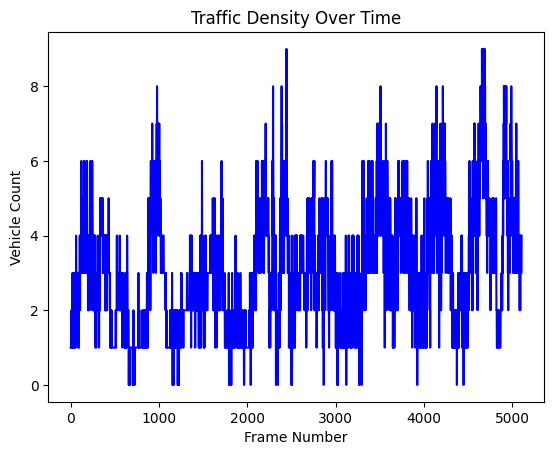

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Re-initialize the video capture object
video_path = '/content/traffic-video-dataset/Talaimari/North-East.mp4'
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Could not open video.")
else:
    print("Video loaded successfully.")

# Process the Video frames

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
density_over_time = []
print(frame_count, '\n', '\n')

# Define the classes considered as vehicles (adjust based on your model's classes)
vehicle_classes = [2, 3, 5, 7] # Example: COCO dataset classes for car, motorcycle, bus, truck

for i in range(frame_count):
    ret, frame = cap.read()
    if not ret:
        print("Error: Could not read frame {0}".format(i))
        break

    # Perform vehicle detection
    results = model(frame, verbose=False) # Set verbose to False to avoid printing detection details for each frame

    # Count vehicles
    vehicle_count = 0
    if results and results[0].boxes:
        for box in results[0].boxes:
            if int(box.cls) in vehicle_classes:
                vehicle_count += 1

    density_over_time.append(vehicle_count)

# Release the video capture object
cap.release()

# Plot traffic density over time
plt.plot(density_over_time, color='blue')
plt.title("Traffic Density Over Time")
plt.xlabel("Frame Number")
plt.ylabel("Vehicle Count")
plt.show()


## **Step 4: Video Preprocessing**
### **Task:**
Preprocess the video data for analysis. Techniques include:
- Frame extraction
- Resizing and normalization
- Noise reduction

### **Mini-task:**
Extract and preprocess a few frames from the video.

```python
# Example: Extract and preprocess frames
def preprocess_frame(frame):
    frame = cv2.resize(frame, (640, 480))  # Resize frame
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)  # Convert to grayscale
    return frame

frames = []
for i in range(10):  # Extract first 10 frames
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(preprocess_frame(frame))

# Display a sample frame
plt.imshow(frames[0], cmap='gray')
plt.axis('off')
plt.show()
```

---

Video loaded successfully.


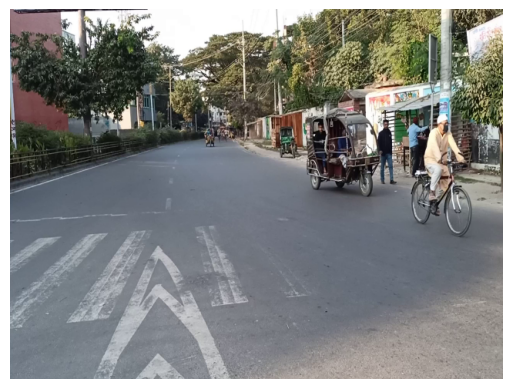

In [ ]:
# Extract and preprocess frames
def preprocess_frame(frame):

    frame = cv2.resize(frame, (640, 480))  # Resize frame
    return frame

# Re-initialize the video capture object
video_path = '/content/traffic-video-dataset/Talaimari/North-East.mp4'
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Could not open video.")
else:
    print("Video loaded successfully.")

frames = []
for i in range(10):  # Extract first 10 frames
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(preprocess_frame(frame))

# Display a sample frame
if frames: # Check if frames list is not empty
    # Display color frame (BGR)
    plt.imshow(frames[0][:, :, ::-1]) # Convert BGR to RGB for matplotlib
    plt.axis('off')
    plt.show()
else:
    print("No frames were read from the video.")

cap.release() # Release the video capture object


## **Step 5: Feature Engineering**
### **Task:**
Extract features from the video data for analysis. Techniques include:
- Vehicle detection using **YOLO**
- Traffic density estimation
- Vehicle tracking

### **Mini-task:**
Perform vehicle detection using a pre-trained YOLO model.

```python
from ultralytics import YOLO

# Load a pre-trained YOLO model
model = YOLO('yolov8n.pt')

# Perform vehicle detection on a frame
results = model(frames[0])

# Visualize the results
results[0].show()
```

---


0: 480x640 5 persons, 2 bicycles, 46.0ms
Speed: 1.4ms preprocess, 46.0ms inference, 3.8ms postprocess per image at shape (1, 3, 480, 640)


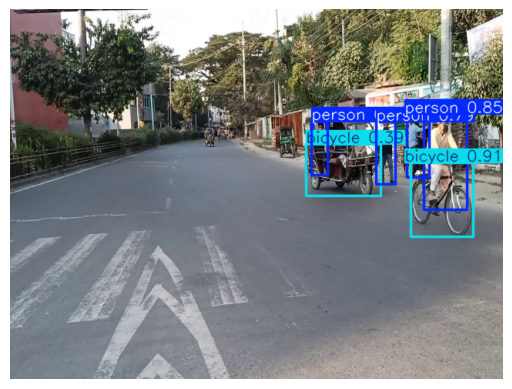

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt # Import matplotlib

# Load a pre-trained YOLO model
model = YOLO('yolov8n.pt')

# Perform vehicle detection ona frame
results = model(frames[0])

# Visualize the resultsly
# results[0].show() # This might not work in all environments

# Display the annotated frame using matplotlib
annotated_frame = results[0].plot() # Get the annotated frame as a NumPy array
plt.imshow(annotated_frame[:, :, ::-1]) # Convert BGR to RGB for matplotlib
plt.axis('off')
plt.show()


## **Step 6: Model Training and Analysis**
### **Task:**
Train a model to analyze traffic patterns, such as predicting traffic density or detecting anomalies. Use classical machine learning models or deep learning models.

### **Mini-task:**
Train a simple model to classify traffic density (low, medium, high) based on vehicle counts.

```python
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import numpy as np

# Example: Train a traffic density classifier
X = np.array(density_over_time).reshape(-1, 1)  # Feature: vehicle count
y = np.where(X < 10, 0, np.where(X < 20, 1, 2))  # Labels: 0=low, 1=medium, 2=high

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Logistic Regression Model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predictions
accuracy = model.score(X_test, y_test)
print(f"Model Accuracy: {accuracy * 100:.2f}%")
```

---


In [ ]:
from sklearn.tree import DecisionTreeClassifier # Import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import numpy as np

# Example: Train a traffic density classifier
X = np.array(density_over_time).reshape(-1, 1)  # Feature: vehicle count
y = np.where(X < 10, 0, np.where(X < 20, 1, 2))  # Labels: 0=low, 1=medium, 2=high

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Decision Tree Model
model = DecisionTreeClassifier() # Use DecisionTreeClassifier
model.fit(X_train, y_train)

# Predictions
accuracy = model.score(X_test, y_test)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 100.00%


## **Step 7: Deployment and Visualization**
### **Task:**
Deploy the traffic monitoring system and visualize the results in real-time. Use tools like **OpenCV** for real-time visualization.

### **Mini-task:**
Create a real-time traffic monitoring dashboard using OpenCV.

```python
# Example: Real-time traffic monitoring
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Perform vehicle detection
    results = model(frame)
    annotated_frame = results[0].plot()

    # Display the annotated frame
    cv2.imshow('Traffic Monitoring', annotated_frame)
    if cv2.waitKey(25) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()
```

---

In [ ]:
from IPython.display import Video, display
import torch

# Check GPU
print("Running on GPU? ->", torch.cuda.is_available())

Running on GPU? -> True


In [ ]:
# Load the YOLO model
from ultralytics import YOLO
model = YOLO('yolov8n.pt')   # lightweight model
model.to('cuda' if torch.cuda.is_available() else 'cpu')

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_s


0: 384x640 5 persons, 1 bicycle, 1 truck, 13.4ms
Speed: 2.2ms preprocess, 13.4ms inference, 6.1ms postprocess per image at shape (1, 3, 384, 640)


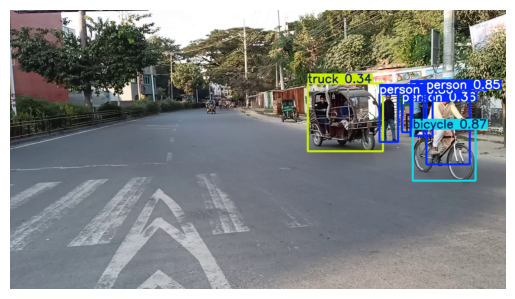


0: 384x640 6 persons, 1 bicycle, 1 truck, 16.2ms
Speed: 4.1ms preprocess, 16.2ms inference, 5.5ms postprocess per image at shape (1, 3, 384, 640)


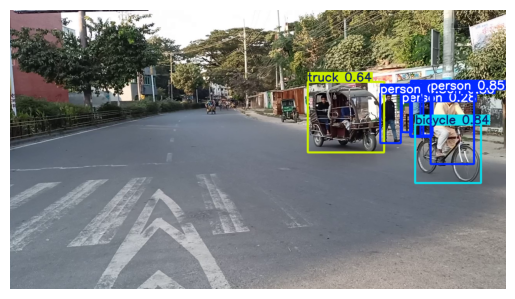


0: 384x640 6 persons, 1 bicycle, 1 truck, 12.4ms
Speed: 4.4ms preprocess, 12.4ms inference, 7.5ms postprocess per image at shape (1, 3, 384, 640)


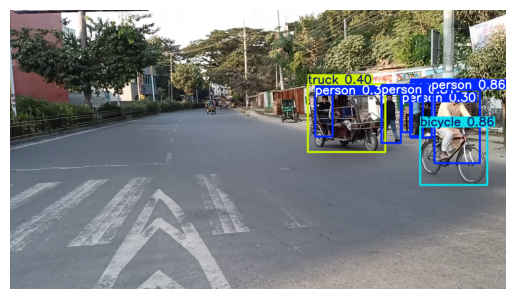


0: 384x640 5 persons, 1 bicycle, 1 truck, 15.1ms
Speed: 4.1ms preprocess, 15.1ms inference, 6.8ms postprocess per image at shape (1, 3, 384, 640)


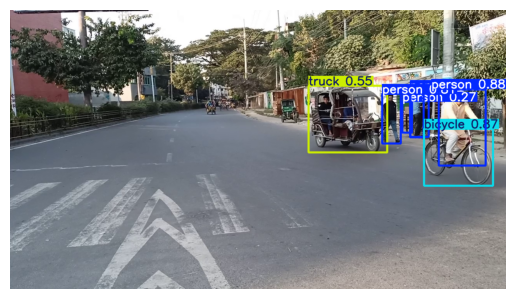


0: 384x640 3 persons, 1 bicycle, 1 truck, 15.1ms
Speed: 4.4ms preprocess, 15.1ms inference, 3.9ms postprocess per image at shape (1, 3, 384, 640)


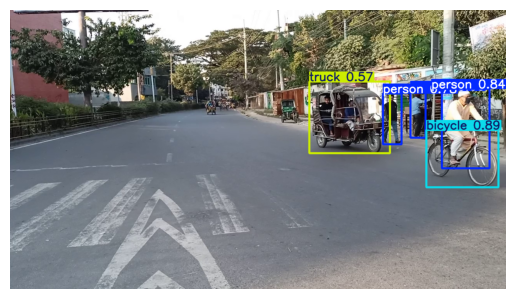


0: 384x640 3 persons, 1 bicycle, 1 truck, 13.7ms
Speed: 3.4ms preprocess, 13.7ms inference, 7.4ms postprocess per image at shape (1, 3, 384, 640)


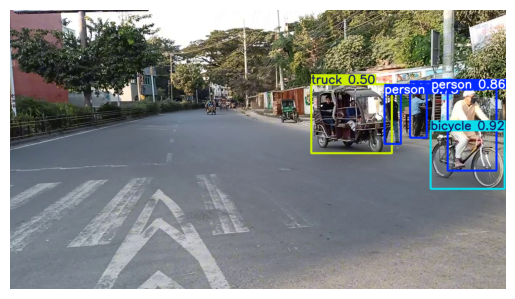


0: 384x640 4 persons, 1 bicycle, 1 truck, 15.7ms
Speed: 5.9ms preprocess, 15.7ms inference, 8.8ms postprocess per image at shape (1, 3, 384, 640)


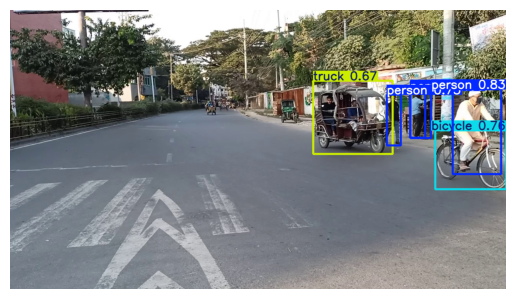


0: 384x640 3 persons, 1 bicycle, 1 truck, 18.7ms
Speed: 2.6ms preprocess, 18.7ms inference, 6.3ms postprocess per image at shape (1, 3, 384, 640)


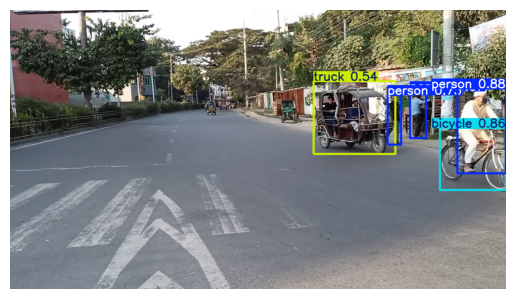


0: 384x640 5 persons, 1 bicycle, 1 motorcycle, 1 truck, 9.6ms
Speed: 3.7ms preprocess, 9.6ms inference, 5.1ms postprocess per image at shape (1, 3, 384, 640)


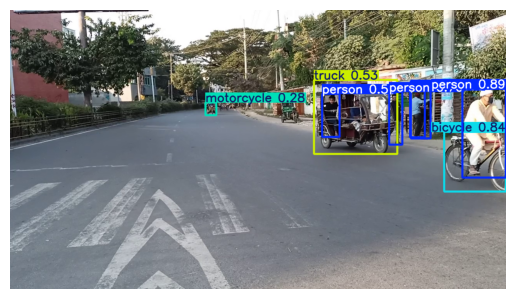


0: 384x640 5 persons, 1 bicycle, 1 motorcycle, 1 truck, 11.7ms
Speed: 2.8ms preprocess, 11.7ms inference, 4.9ms postprocess per image at shape (1, 3, 384, 640)


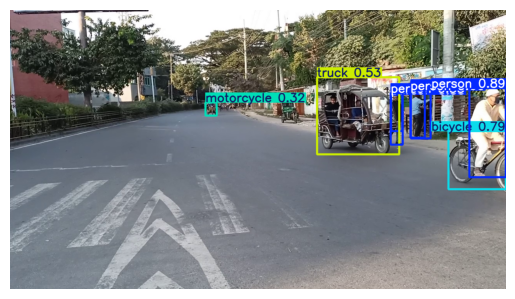


0: 384x640 3 persons, 1 bicycle, 1 truck, 13.8ms
Speed: 4.8ms preprocess, 13.8ms inference, 4.1ms postprocess per image at shape (1, 3, 384, 640)


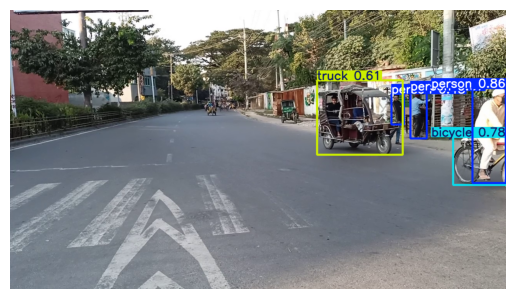


0: 384x640 4 persons, 1 bicycle, 1 motorcycle, 1 truck, 8.9ms
Speed: 2.7ms preprocess, 8.9ms inference, 4.8ms postprocess per image at shape (1, 3, 384, 640)


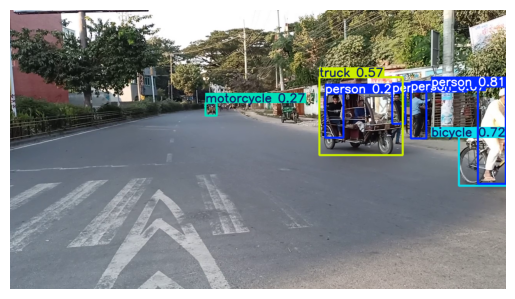


0: 384x640 3 persons, 1 bicycle, 1 motorcycle, 1 truck, 8.3ms
Speed: 2.3ms preprocess, 8.3ms inference, 4.0ms postprocess per image at shape (1, 3, 384, 640)


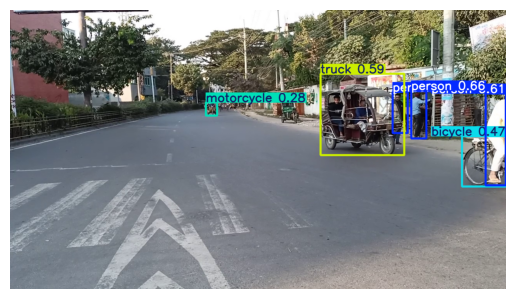


0: 384x640 3 persons, 1 bicycle, 1 motorcycle, 1 truck, 10.5ms
Speed: 2.4ms preprocess, 10.5ms inference, 5.9ms postprocess per image at shape (1, 3, 384, 640)


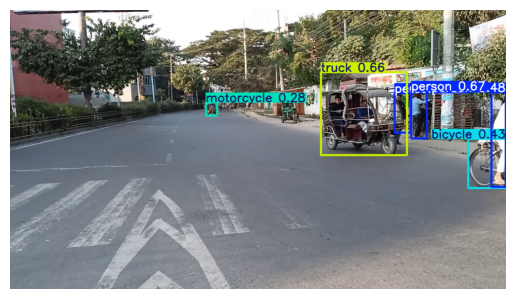


0: 384x640 1 person, 1 bicycle, 1 motorcycle, 1 truck, 11.7ms
Speed: 2.1ms preprocess, 11.7ms inference, 3.5ms postprocess per image at shape (1, 3, 384, 640)


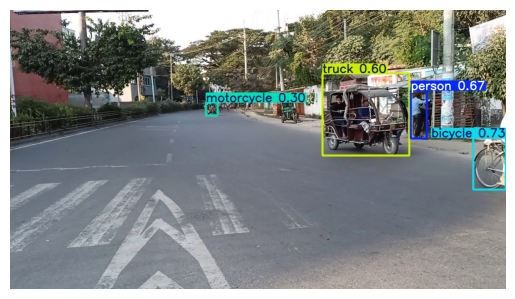


0: 384x640 1 person, 1 bicycle, 1 truck, 11.9ms
Speed: 2.9ms preprocess, 11.9ms inference, 3.0ms postprocess per image at shape (1, 3, 384, 640)


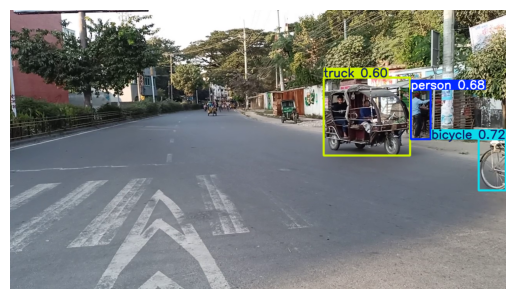


0: 384x640 2 persons, 1 bicycle, 1 truck, 8.1ms
Speed: 3.1ms preprocess, 8.1ms inference, 3.0ms postprocess per image at shape (1, 3, 384, 640)


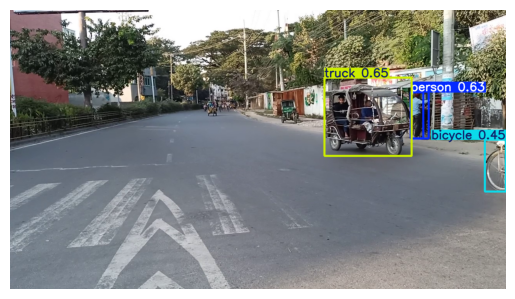


0: 384x640 2 persons, 1 bicycle, 1 motorcycle, 1 truck, 10.7ms
Speed: 5.3ms preprocess, 10.7ms inference, 3.5ms postprocess per image at shape (1, 3, 384, 640)


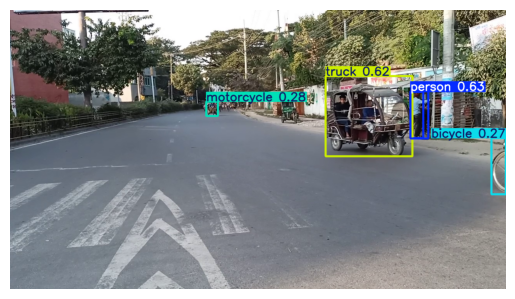


0: 384x640 1 person, 1 motorcycle, 1 truck, 8.4ms
Speed: 4.3ms preprocess, 8.4ms inference, 3.1ms postprocess per image at shape (1, 3, 384, 640)


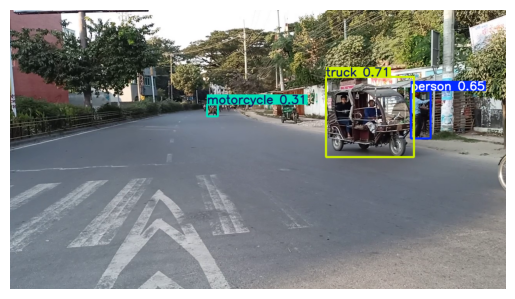


0: 384x640 1 person, 1 motorcycle, 1 truck, 8.7ms
Speed: 3.4ms preprocess, 8.7ms inference, 2.6ms postprocess per image at shape (1, 3, 384, 640)


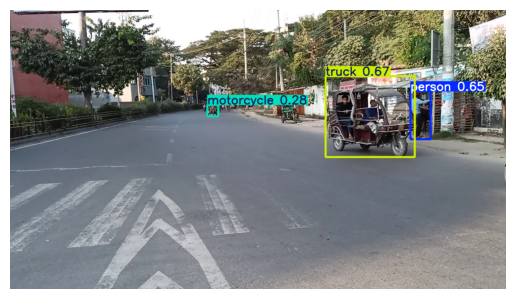


0: 384x640 2 persons, 1 motorcycle, 1 truck, 10.4ms
Speed: 3.6ms preprocess, 10.4ms inference, 2.9ms postprocess per image at shape (1, 3, 384, 640)


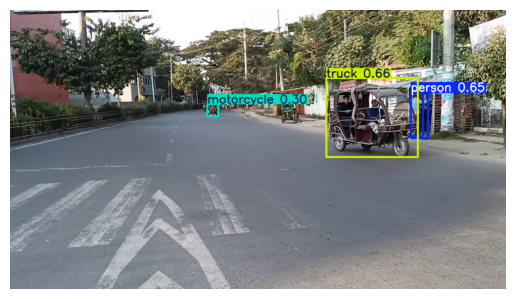


0: 384x640 2 persons, 2 motorcycles, 1 truck, 8.4ms
Speed: 3.3ms preprocess, 8.4ms inference, 3.5ms postprocess per image at shape (1, 3, 384, 640)


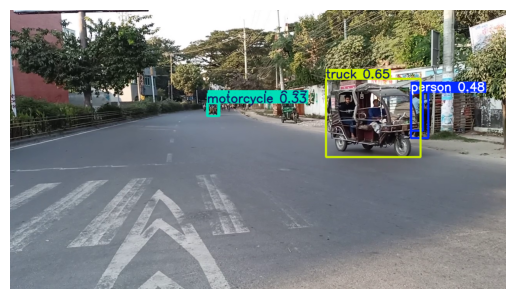


0: 384x640 1 truck, 7.7ms
Speed: 5.5ms preprocess, 7.7ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)


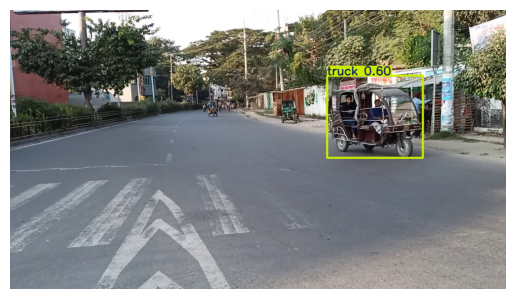


0: 384x640 1 truck, 9.3ms
Speed: 2.7ms preprocess, 9.3ms inference, 1.9ms postprocess per image at shape (1, 3, 384, 640)


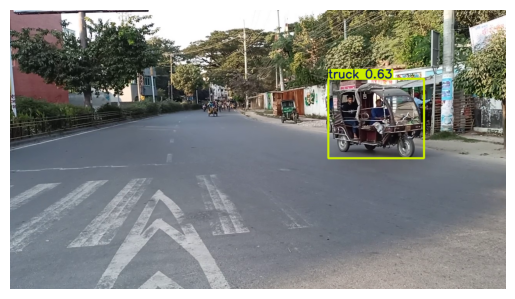


0: 384x640 1 truck, 9.5ms
Speed: 6.0ms preprocess, 9.5ms inference, 1.9ms postprocess per image at shape (1, 3, 384, 640)


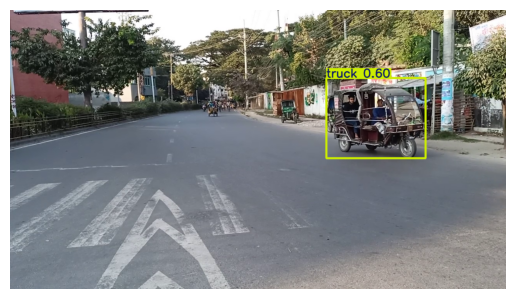


0: 384x640 1 person, 1 motorcycle, 1 truck, 13.3ms
Speed: 3.2ms preprocess, 13.3ms inference, 3.0ms postprocess per image at shape (1, 3, 384, 640)


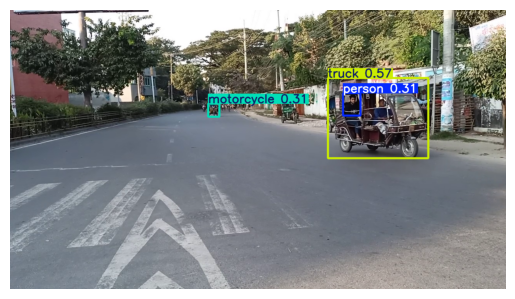


0: 384x640 1 motorcycle, 1 truck, 8.6ms
Speed: 2.1ms preprocess, 8.6ms inference, 2.6ms postprocess per image at shape (1, 3, 384, 640)


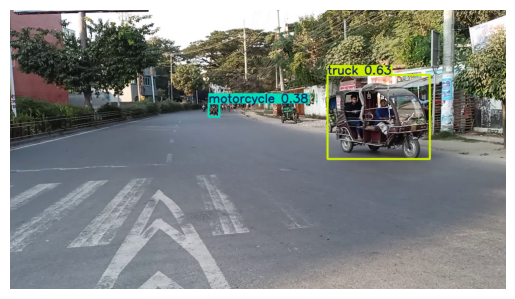


0: 384x640 3 persons, 1 motorcycle, 1 truck, 15.5ms
Speed: 5.0ms preprocess, 15.5ms inference, 4.3ms postprocess per image at shape (1, 3, 384, 640)


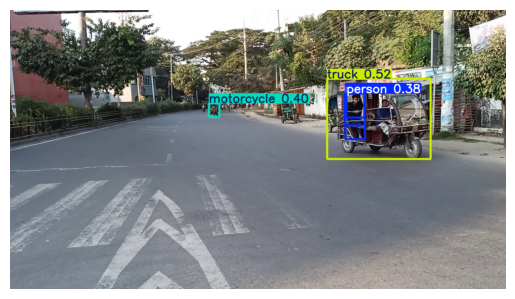


0: 384x640 2 persons, 1 motorcycle, 1 truck, 10.8ms
Speed: 4.6ms preprocess, 10.8ms inference, 3.4ms postprocess per image at shape (1, 3, 384, 640)


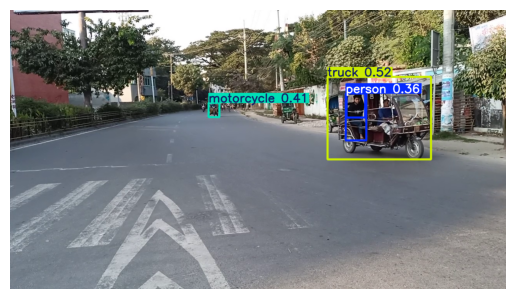


0: 384x640 1 person, 1 motorcycle, 1 truck, 15.4ms
Speed: 4.3ms preprocess, 15.4ms inference, 2.9ms postprocess per image at shape (1, 3, 384, 640)


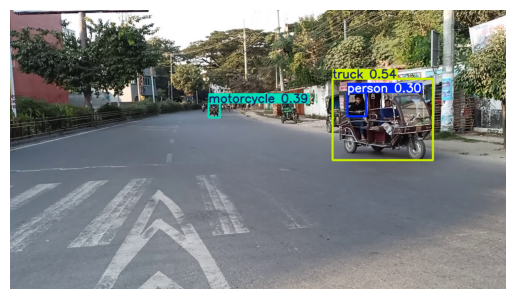


0: 384x640 1 person, 1 motorcycle, 1 truck, 8.6ms
Speed: 2.0ms preprocess, 8.6ms inference, 2.7ms postprocess per image at shape (1, 3, 384, 640)


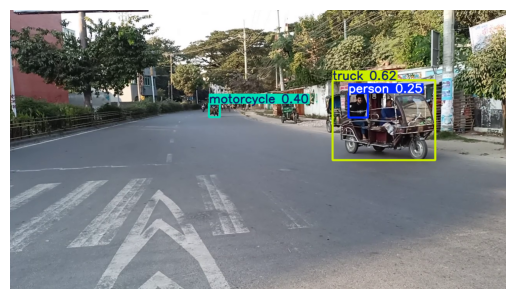


0: 384x640 1 person, 2 motorcycles, 1 truck, 13.6ms
Speed: 4.2ms preprocess, 13.6ms inference, 5.7ms postprocess per image at shape (1, 3, 384, 640)


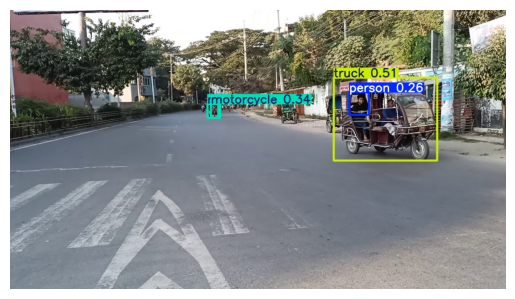


0: 384x640 1 person, 1 truck, 15.0ms
Speed: 2.1ms preprocess, 15.0ms inference, 2.4ms postprocess per image at shape (1, 3, 384, 640)


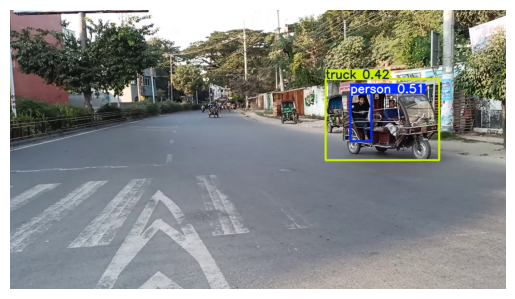


0: 384x640 2 persons, 1 motorcycle, 1 truck, 8.7ms
Speed: 3.4ms preprocess, 8.7ms inference, 2.8ms postprocess per image at shape (1, 3, 384, 640)


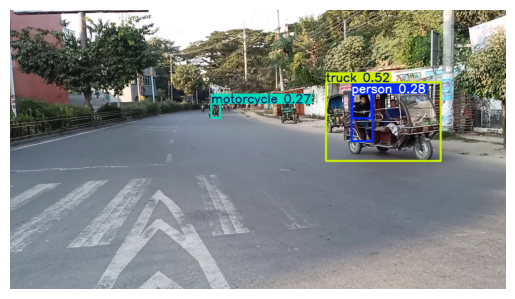


0: 384x640 1 motorcycle, 1 truck, 12.2ms
Speed: 4.7ms preprocess, 12.2ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)


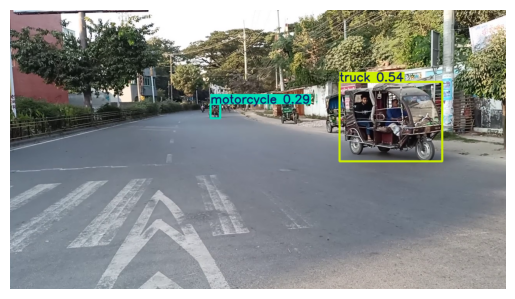


0: 384x640 1 person, 2 motorcycles, 1 truck, 14.3ms
Speed: 5.2ms preprocess, 14.3ms inference, 2.8ms postprocess per image at shape (1, 3, 384, 640)


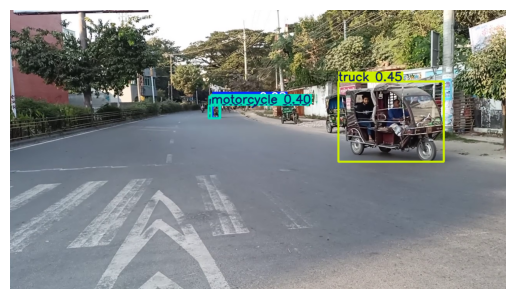


0: 384x640 1 person, 1 motorcycle, 1 truck, 12.0ms
Speed: 4.7ms preprocess, 12.0ms inference, 3.0ms postprocess per image at shape (1, 3, 384, 640)


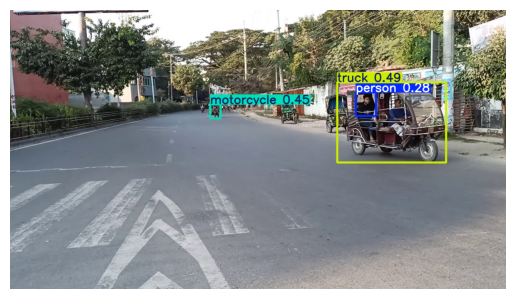


0: 384x640 2 persons, 1 motorcycle, 1 truck, 13.5ms
Speed: 4.1ms preprocess, 13.5ms inference, 4.5ms postprocess per image at shape (1, 3, 384, 640)


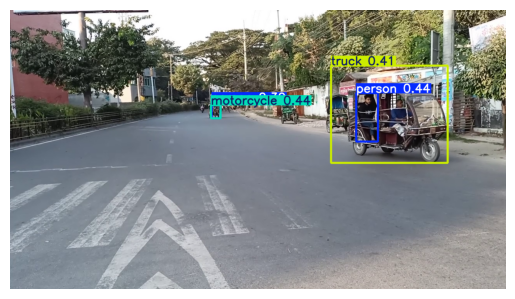


0: 384x640 2 persons, 1 motorcycle, 10.0ms
Speed: 4.3ms preprocess, 10.0ms inference, 2.7ms postprocess per image at shape (1, 3, 384, 640)


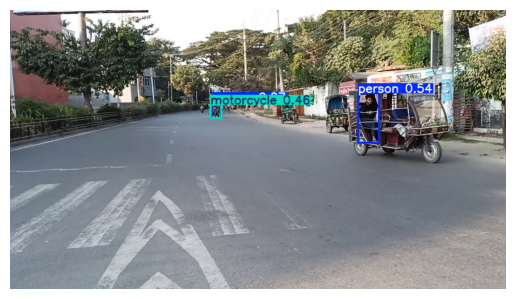


0: 384x640 1 person, 1 motorcycle, 8.5ms
Speed: 4.3ms preprocess, 8.5ms inference, 2.1ms postprocess per image at shape (1, 3, 384, 640)


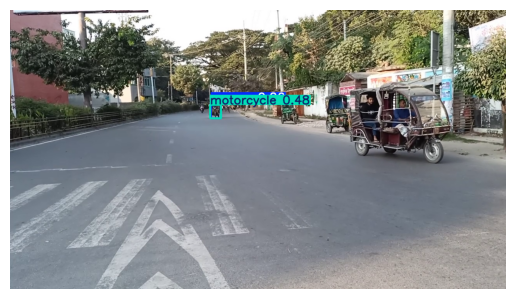


0: 384x640 2 persons, 2 motorcycles, 1 truck, 7.3ms
Speed: 3.1ms preprocess, 7.3ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)


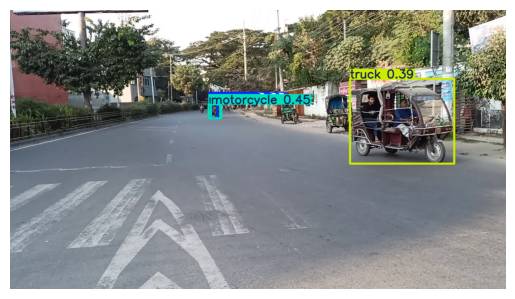


0: 384x640 2 persons, 2 motorcycles, 1 truck, 14.3ms
Speed: 2.5ms preprocess, 14.3ms inference, 3.1ms postprocess per image at shape (1, 3, 384, 640)


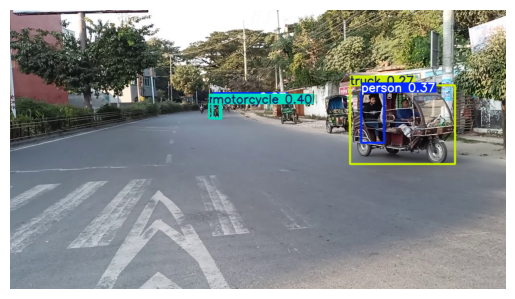


0: 384x640 1 person, 2 motorcycles, 1 truck, 14.0ms
Speed: 2.0ms preprocess, 14.0ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)


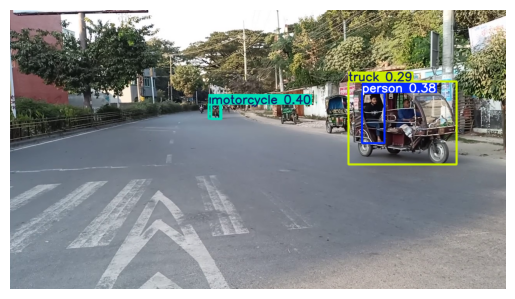


0: 384x640 1 person, 1 motorcycle, 1 truck, 14.1ms
Speed: 5.2ms preprocess, 14.1ms inference, 3.9ms postprocess per image at shape (1, 3, 384, 640)


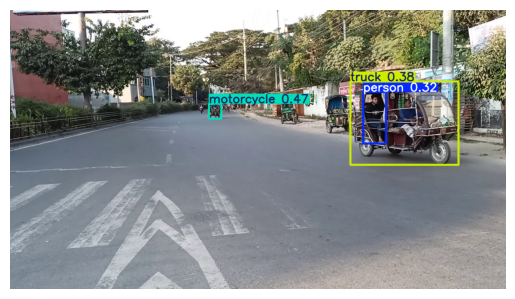


0: 384x640 1 motorcycle, 1 truck, 9.7ms
Speed: 2.2ms preprocess, 9.7ms inference, 2.5ms postprocess per image at shape (1, 3, 384, 640)


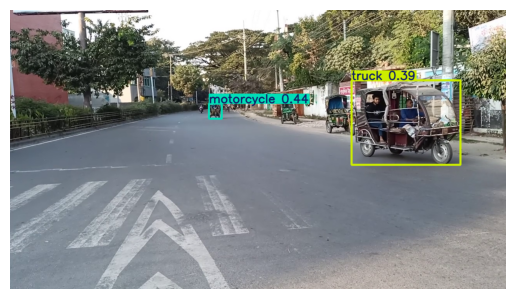


0: 384x640 1 person, 1 motorcycle, 14.4ms
Speed: 3.1ms preprocess, 14.4ms inference, 3.8ms postprocess per image at shape (1, 3, 384, 640)


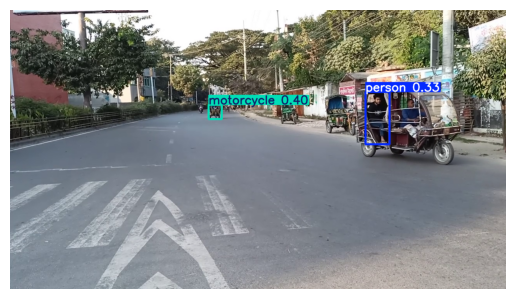


0: 384x640 1 person, 1 motorcycle, 1 truck, 14.4ms
Speed: 2.1ms preprocess, 14.4ms inference, 5.4ms postprocess per image at shape (1, 3, 384, 640)


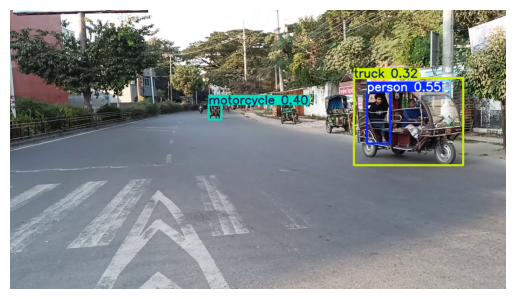


0: 384x640 1 person, 1 motorcycle, 1 truck, 20.7ms
Speed: 8.2ms preprocess, 20.7ms inference, 3.0ms postprocess per image at shape (1, 3, 384, 640)


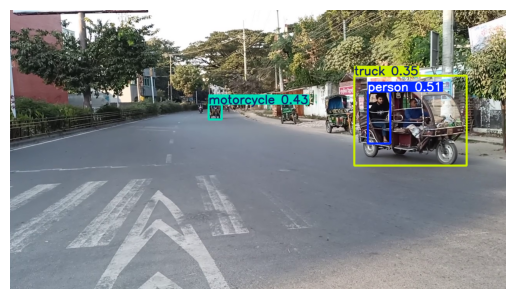


0: 384x640 2 persons, 1 motorcycle, 1 truck, 14.7ms
Speed: 5.9ms preprocess, 14.7ms inference, 3.6ms postprocess per image at shape (1, 3, 384, 640)


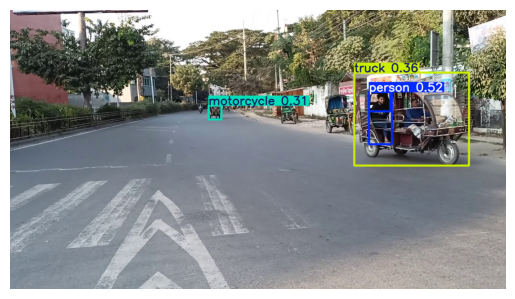


0: 384x640 1 person, 1 motorcycle, 1 truck, 23.9ms
Speed: 4.0ms preprocess, 23.9ms inference, 2.5ms postprocess per image at shape (1, 3, 384, 640)


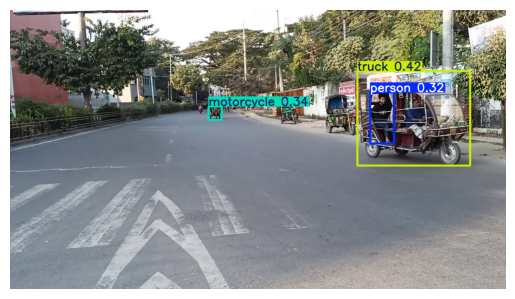


0: 384x640 1 motorcycle, 1 truck, 16.5ms
Speed: 8.9ms preprocess, 16.5ms inference, 2.1ms postprocess per image at shape (1, 3, 384, 640)


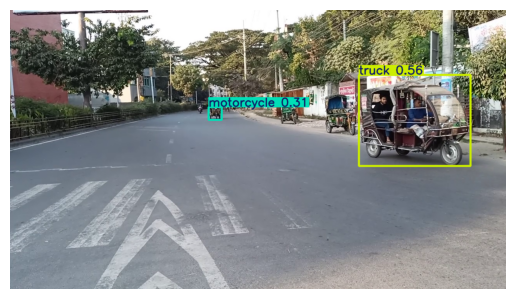


0: 384x640 1 motorcycle, 1 truck, 24.6ms
Speed: 5.3ms preprocess, 24.6ms inference, 5.9ms postprocess per image at shape (1, 3, 384, 640)


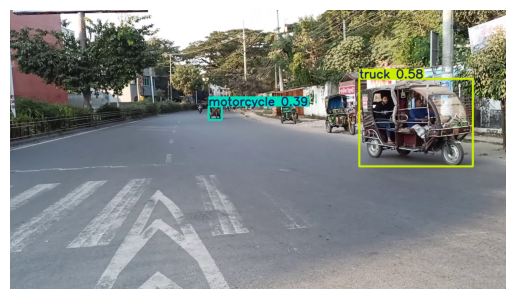


0: 384x640 1 person, 1 motorcycle, 1 truck, 12.1ms
Speed: 3.7ms preprocess, 12.1ms inference, 3.4ms postprocess per image at shape (1, 3, 384, 640)


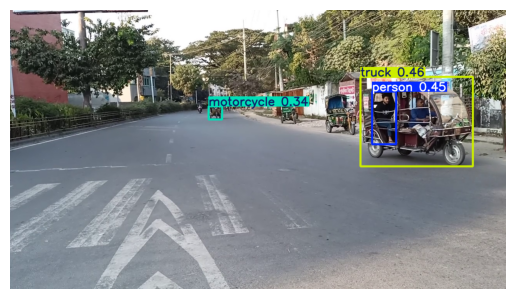


0: 384x640 2 persons, 1 motorcycle, 1 truck, 23.9ms
Speed: 7.1ms preprocess, 23.9ms inference, 5.0ms postprocess per image at shape (1, 3, 384, 640)


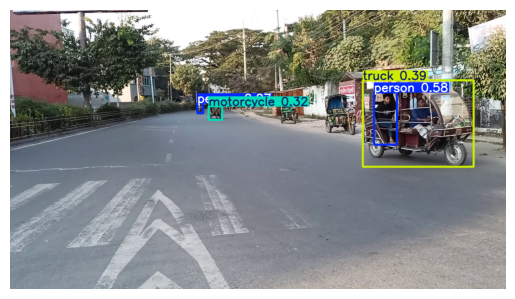


0: 384x640 3 persons, 1 motorcycle, 1 truck, 17.5ms
Speed: 3.2ms preprocess, 17.5ms inference, 8.4ms postprocess per image at shape (1, 3, 384, 640)


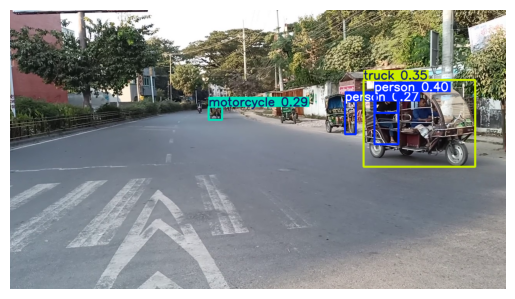


0: 384x640 1 person, 1 motorcycle, 1 truck, 17.9ms
Speed: 2.1ms preprocess, 17.9ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)


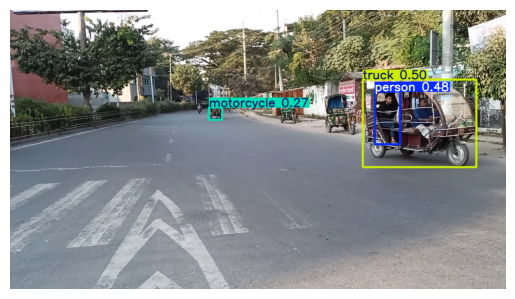


0: 384x640 1 person, 1 motorcycle, 1 truck, 10.2ms
Speed: 3.8ms preprocess, 10.2ms inference, 2.9ms postprocess per image at shape (1, 3, 384, 640)


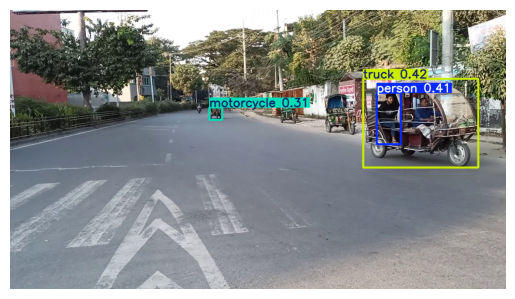


0: 384x640 3 persons, 1 truck, 15.7ms
Speed: 7.1ms preprocess, 15.7ms inference, 3.2ms postprocess per image at shape (1, 3, 384, 640)


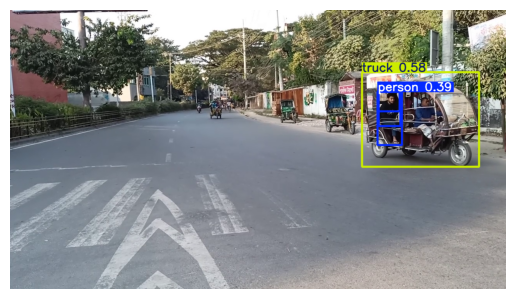


0: 384x640 4 persons, 1 truck, 13.8ms
Speed: 2.0ms preprocess, 13.8ms inference, 4.0ms postprocess per image at shape (1, 3, 384, 640)


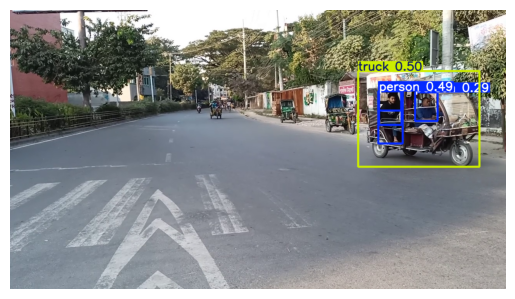


0: 384x640 2 persons, 1 truck, 8.2ms
Speed: 2.4ms preprocess, 8.2ms inference, 2.6ms postprocess per image at shape (1, 3, 384, 640)


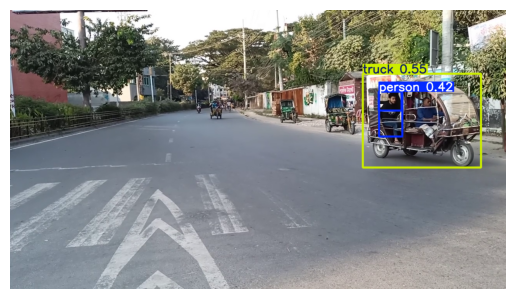


0: 384x640 1 person, 2 motorcycles, 2 trucks, 12.7ms
Speed: 5.4ms preprocess, 12.7ms inference, 4.2ms postprocess per image at shape (1, 3, 384, 640)


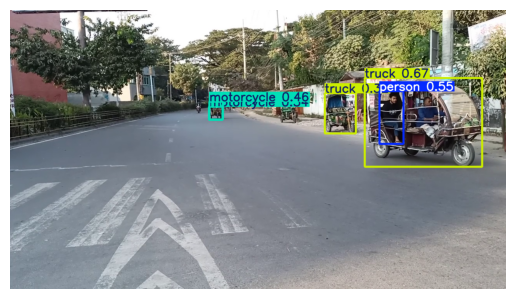


0: 384x640 2 persons, 2 motorcycles, 2 trucks, 13.3ms
Speed: 6.1ms preprocess, 13.3ms inference, 4.1ms postprocess per image at shape (1, 3, 384, 640)


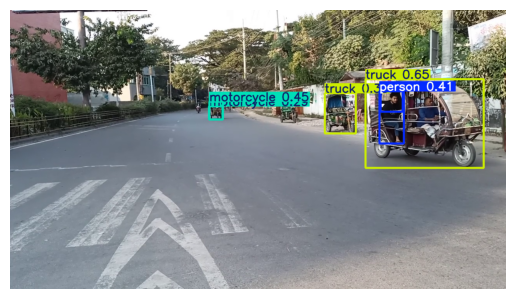


0: 384x640 2 persons, 1 motorcycle, 2 trucks, 9.7ms
Speed: 3.5ms preprocess, 9.7ms inference, 3.9ms postprocess per image at shape (1, 3, 384, 640)


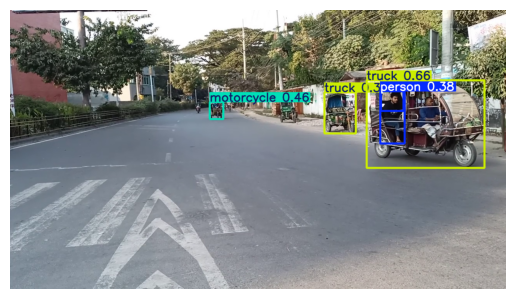


0: 384x640 3 persons, 1 motorcycle, 2 trucks, 9.9ms
Speed: 5.1ms preprocess, 9.9ms inference, 3.8ms postprocess per image at shape (1, 3, 384, 640)


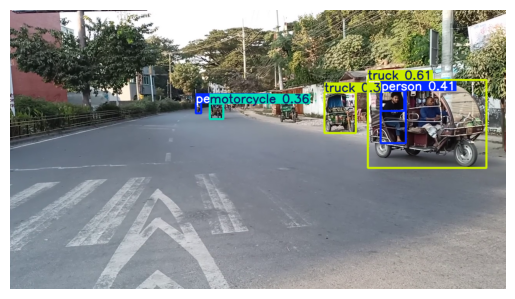


0: 384x640 4 persons, 1 motorcycle, 2 trucks, 9.7ms
Speed: 2.1ms preprocess, 9.7ms inference, 4.4ms postprocess per image at shape (1, 3, 384, 640)


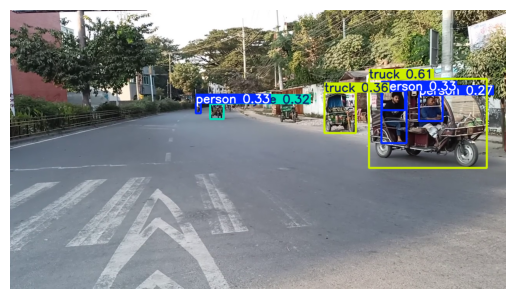


0: 384x640 4 persons, 1 motorcycle, 2 trucks, 10.6ms
Speed: 5.1ms preprocess, 10.6ms inference, 4.2ms postprocess per image at shape (1, 3, 384, 640)


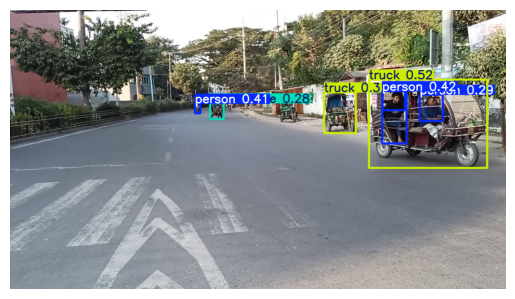


0: 384x640 3 persons, 2 trucks, 8.7ms
Speed: 2.7ms preprocess, 8.7ms inference, 3.7ms postprocess per image at shape (1, 3, 384, 640)


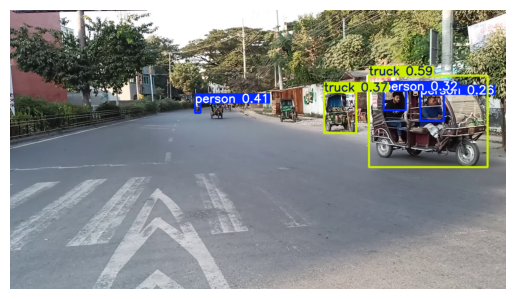


0: 384x640 2 persons, 2 trucks, 14.3ms
Speed: 4.0ms preprocess, 14.3ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)


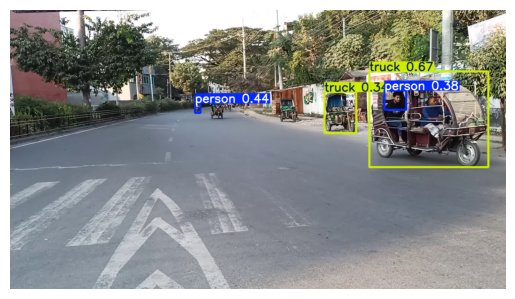


0: 384x640 3 persons, 2 trucks, 8.7ms
Speed: 4.0ms preprocess, 8.7ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)


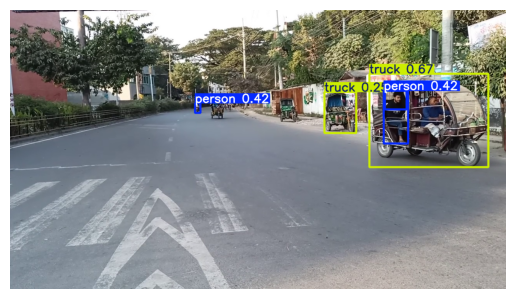


0: 384x640 2 persons, 2 trucks, 12.8ms
Speed: 3.8ms preprocess, 12.8ms inference, 3.1ms postprocess per image at shape (1, 3, 384, 640)


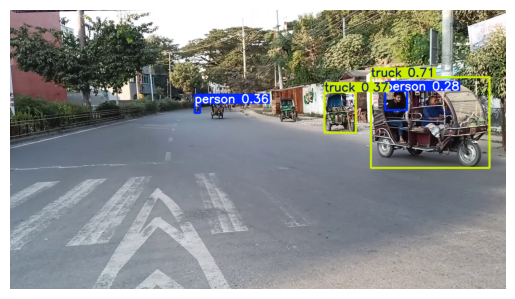


0: 384x640 4 persons, 2 trucks, 10.7ms
Speed: 2.6ms preprocess, 10.7ms inference, 4.5ms postprocess per image at shape (1, 3, 384, 640)


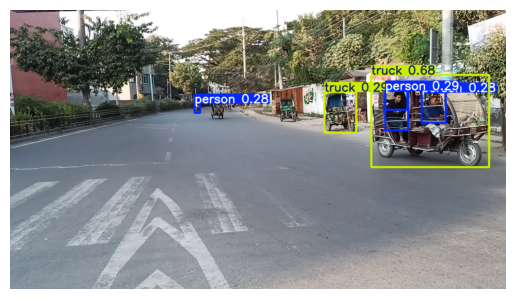


0: 384x640 4 persons, 2 trucks, 13.1ms
Speed: 2.2ms preprocess, 13.1ms inference, 4.5ms postprocess per image at shape (1, 3, 384, 640)


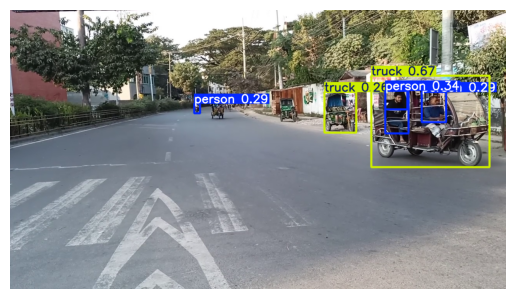


0: 384x640 5 persons, 2 trucks, 9.6ms
Speed: 2.2ms preprocess, 9.6ms inference, 4.3ms postprocess per image at shape (1, 3, 384, 640)


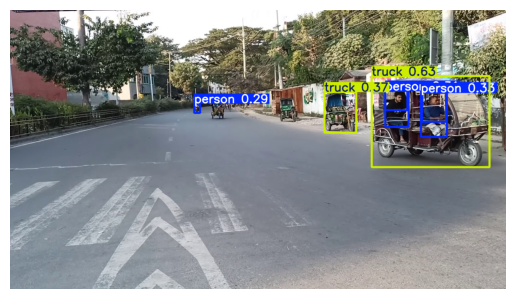


0: 384x640 4 persons, 1 motorcycle, 2 trucks, 9.1ms
Speed: 2.7ms preprocess, 9.1ms inference, 5.4ms postprocess per image at shape (1, 3, 384, 640)


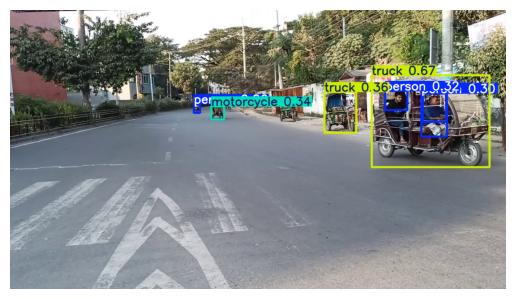


0: 384x640 5 persons, 1 motorcycle, 2 trucks, 10.9ms
Speed: 4.5ms preprocess, 10.9ms inference, 5.9ms postprocess per image at shape (1, 3, 384, 640)


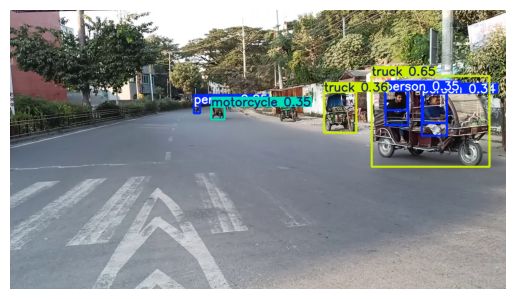


0: 384x640 3 persons, 1 motorcycle, 2 trucks, 13.2ms
Speed: 4.2ms preprocess, 13.2ms inference, 4.3ms postprocess per image at shape (1, 3, 384, 640)


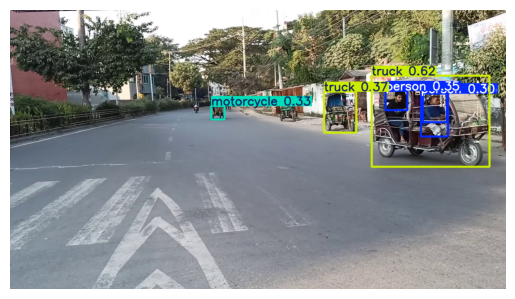


0: 384x640 2 persons, 1 motorcycle, 2 trucks, 9.5ms
Speed: 3.8ms preprocess, 9.5ms inference, 3.8ms postprocess per image at shape (1, 3, 384, 640)


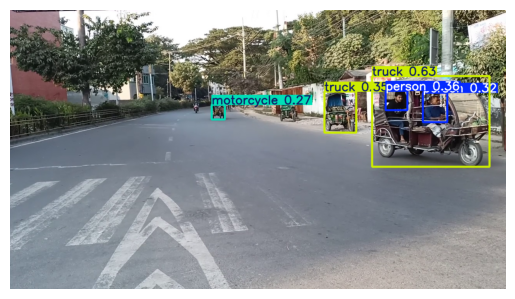


0: 384x640 3 persons, 1 motorcycle, 2 trucks, 13.8ms
Speed: 4.2ms preprocess, 13.8ms inference, 4.1ms postprocess per image at shape (1, 3, 384, 640)


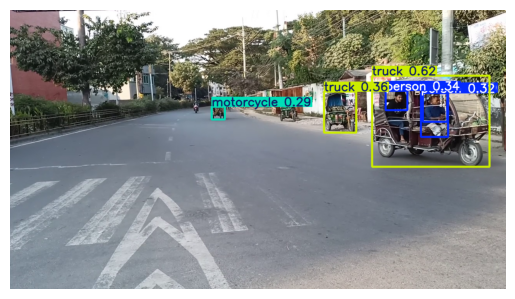


0: 384x640 3 persons, 2 trucks, 7.6ms
Speed: 2.0ms preprocess, 7.6ms inference, 3.7ms postprocess per image at shape (1, 3, 384, 640)


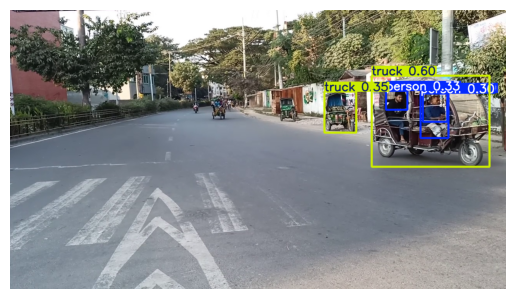


0: 384x640 2 persons, 1 motorcycle, 2 trucks, 11.8ms
Speed: 2.9ms preprocess, 11.8ms inference, 3.8ms postprocess per image at shape (1, 3, 384, 640)


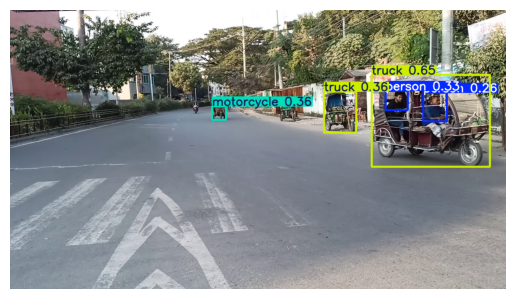


0: 384x640 3 persons, 1 motorcycle, 2 trucks, 7.9ms
Speed: 2.3ms preprocess, 7.9ms inference, 4.0ms postprocess per image at shape (1, 3, 384, 640)


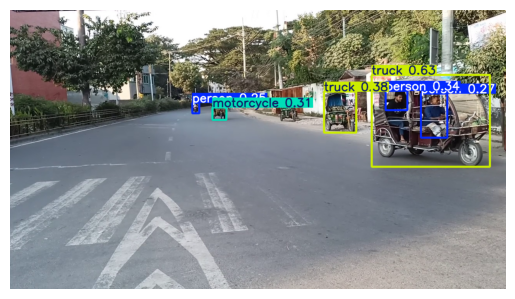


0: 384x640 2 persons, 1 motorcycle, 2 trucks, 14.9ms
Speed: 4.1ms preprocess, 14.9ms inference, 3.2ms postprocess per image at shape (1, 3, 384, 640)


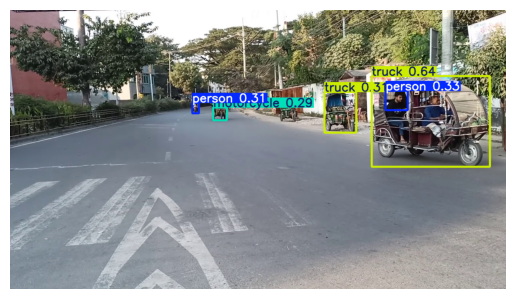


0: 384x640 3 persons, 1 motorcycle, 2 trucks, 8.0ms
Speed: 2.1ms preprocess, 8.0ms inference, 4.1ms postprocess per image at shape (1, 3, 384, 640)


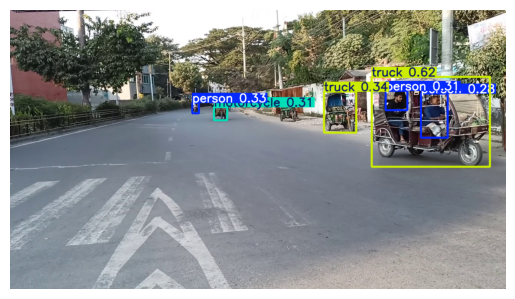


0: 384x640 3 persons, 1 motorcycle, 2 trucks, 14.8ms
Speed: 4.9ms preprocess, 14.8ms inference, 3.6ms postprocess per image at shape (1, 3, 384, 640)


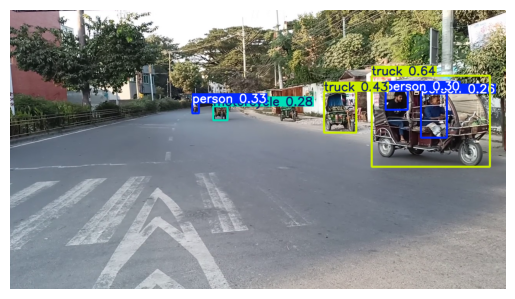


0: 384x640 2 persons, 1 motorcycle, 2 trucks, 8.1ms
Speed: 3.7ms preprocess, 8.1ms inference, 3.4ms postprocess per image at shape (1, 3, 384, 640)


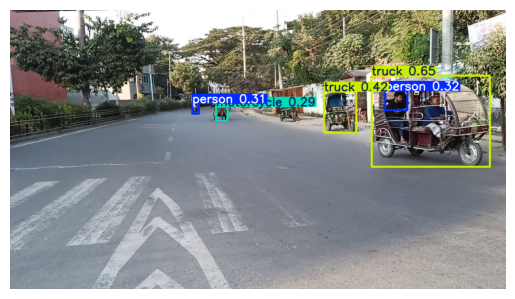


0: 384x640 2 persons, 1 motorcycle, 2 trucks, 9.6ms
Speed: 2.0ms preprocess, 9.6ms inference, 3.8ms postprocess per image at shape (1, 3, 384, 640)


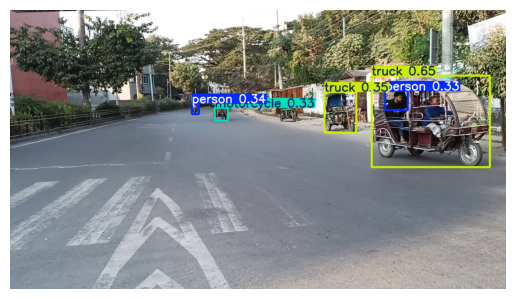


0: 384x640 4 persons, 1 motorcycle, 2 trucks, 8.9ms
Speed: 2.9ms preprocess, 8.9ms inference, 4.4ms postprocess per image at shape (1, 3, 384, 640)


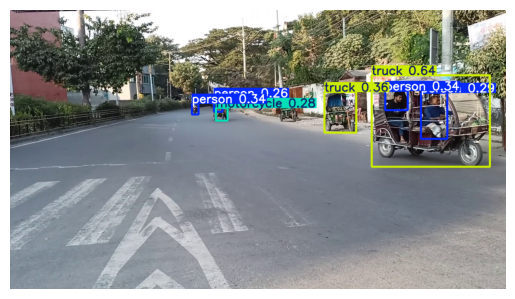


0: 384x640 4 persons, 2 trucks, 13.7ms
Speed: 4.2ms preprocess, 13.7ms inference, 4.6ms postprocess per image at shape (1, 3, 384, 640)


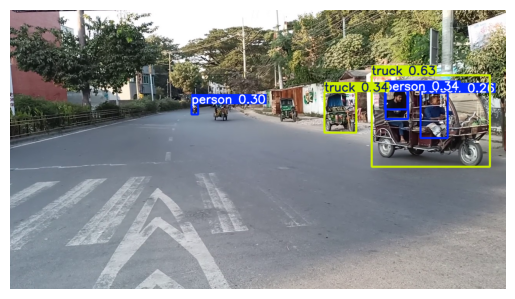


0: 384x640 4 persons, 2 trucks, 9.0ms
Speed: 4.0ms preprocess, 9.0ms inference, 4.0ms postprocess per image at shape (1, 3, 384, 640)


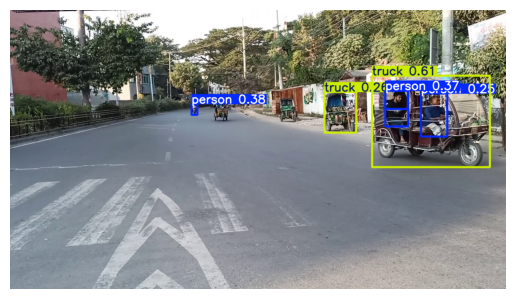


0: 384x640 3 persons, 1 truck, 12.2ms
Speed: 2.1ms preprocess, 12.2ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)


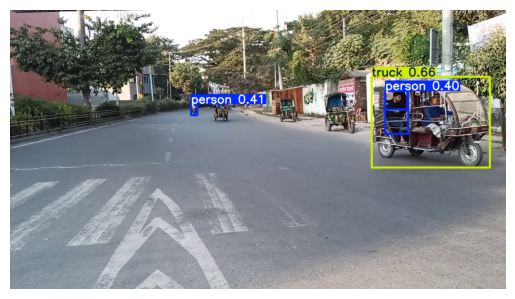


0: 384x640 3 persons, 2 trucks, 7.6ms
Speed: 2.3ms preprocess, 7.6ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)


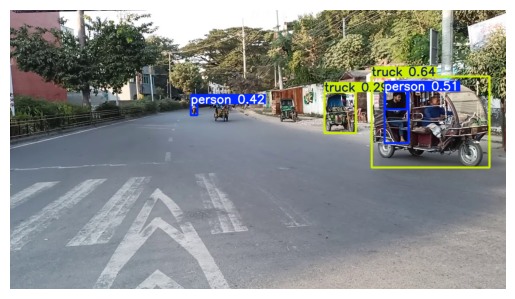


0: 384x640 4 persons, 2 trucks, 14.0ms
Speed: 4.1ms preprocess, 14.0ms inference, 4.2ms postprocess per image at shape (1, 3, 384, 640)


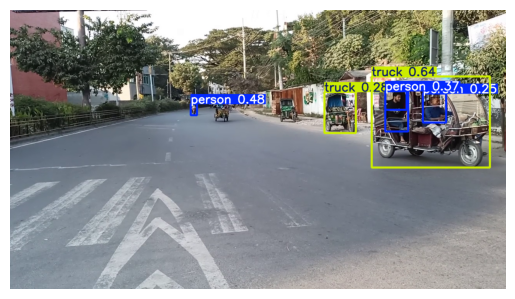


0: 384x640 4 persons, 2 trucks, 14.9ms
Speed: 4.5ms preprocess, 14.9ms inference, 6.5ms postprocess per image at shape (1, 3, 384, 640)


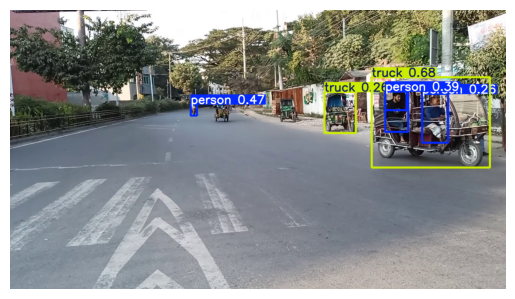


0: 384x640 4 persons, 1 truck, 16.1ms
Speed: 2.2ms preprocess, 16.1ms inference, 7.7ms postprocess per image at shape (1, 3, 384, 640)


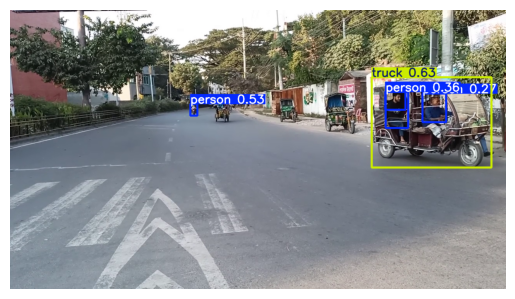


0: 384x640 2 persons, 1 motorcycle, 2 trucks, 13.3ms
Speed: 2.2ms preprocess, 13.3ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)


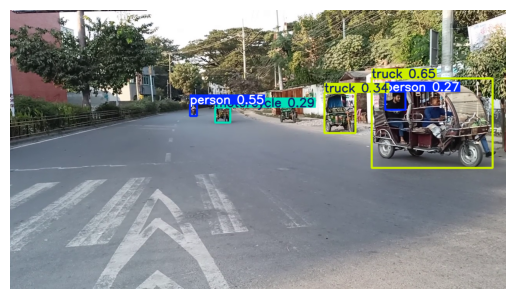


0: 384x640 3 persons, 1 motorcycle, 2 trucks, 11.5ms
Speed: 3.0ms preprocess, 11.5ms inference, 7.9ms postprocess per image at shape (1, 3, 384, 640)


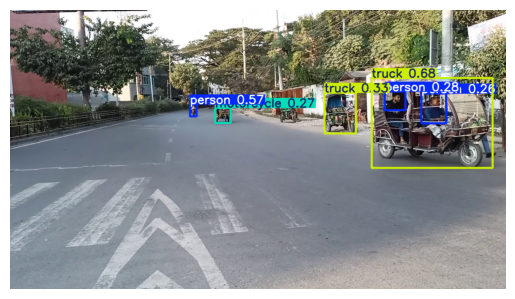


0: 384x640 2 persons, 2 trucks, 13.9ms
Speed: 4.3ms preprocess, 13.9ms inference, 2.9ms postprocess per image at shape (1, 3, 384, 640)


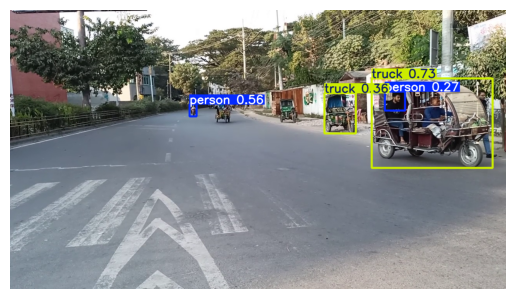


0: 384x640 2 persons, 1 motorcycle, 2 trucks, 20.9ms
Speed: 5.1ms preprocess, 20.9ms inference, 3.2ms postprocess per image at shape (1, 3, 384, 640)


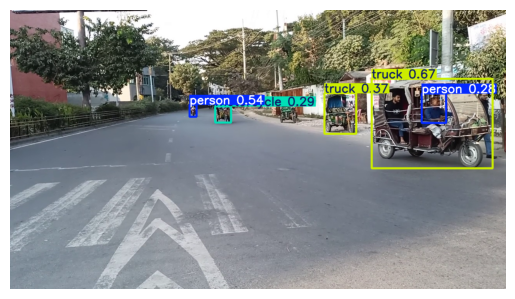


0: 384x640 5 persons, 1 motorcycle, 2 trucks, 15.0ms
Speed: 4.1ms preprocess, 15.0ms inference, 6.7ms postprocess per image at shape (1, 3, 384, 640)


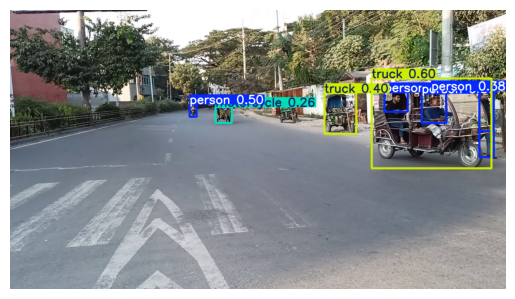


0: 384x640 6 persons, 1 motorcycle, 2 trucks, 16.8ms
Speed: 6.7ms preprocess, 16.8ms inference, 7.9ms postprocess per image at shape (1, 3, 384, 640)


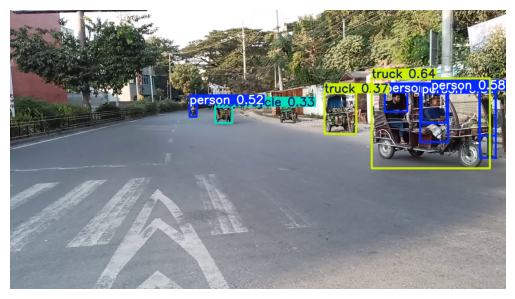


0: 384x640 7 persons, 1 motorcycle, 2 trucks, 13.5ms
Speed: 4.6ms preprocess, 13.5ms inference, 10.0ms postprocess per image at shape (1, 3, 384, 640)


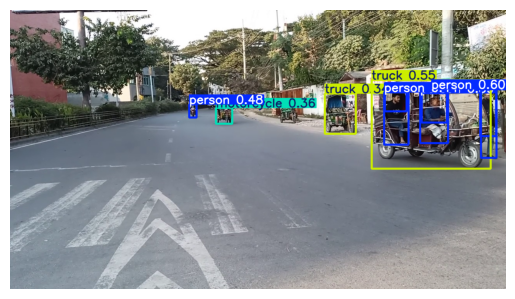


0: 384x640 6 persons, 1 motorcycle, 1 truck, 9.7ms
Speed: 2.4ms preprocess, 9.7ms inference, 8.2ms postprocess per image at shape (1, 3, 384, 640)


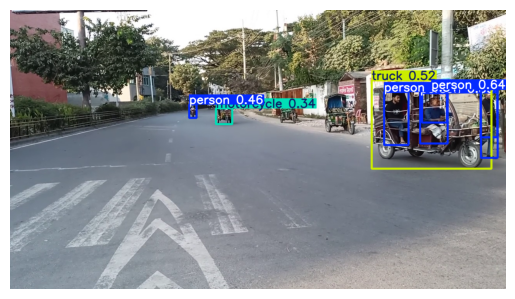


0: 384x640 4 persons, 2 motorcycles, 1 truck, 12.7ms
Speed: 4.0ms preprocess, 12.7ms inference, 6.7ms postprocess per image at shape (1, 3, 384, 640)


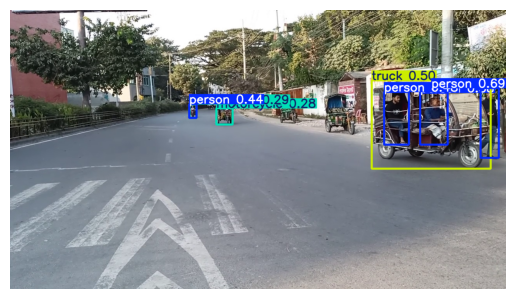


0: 384x640 4 persons, 3 motorcycles, 1 truck, 19.5ms
Speed: 3.5ms preprocess, 19.5ms inference, 8.0ms postprocess per image at shape (1, 3, 384, 640)


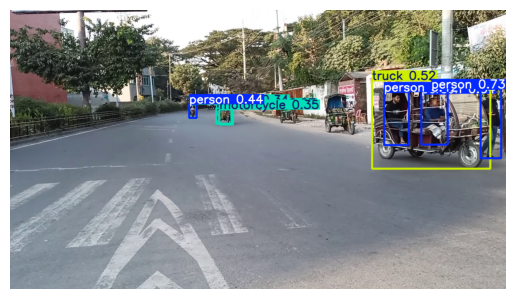


0: 384x640 3 persons, 2 motorcycles, 1 truck, 1 fire hydrant, 9.0ms
Speed: 3.1ms preprocess, 9.0ms inference, 4.5ms postprocess per image at shape (1, 3, 384, 640)


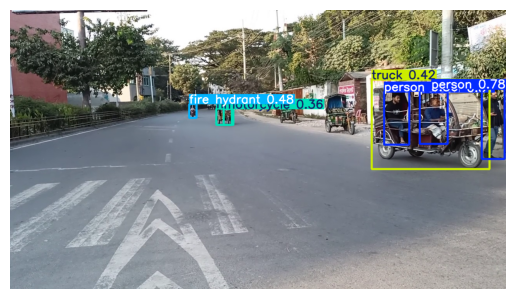


0: 384x640 4 persons, 2 motorcycles, 1 truck, 1 fire hydrant, 14.1ms
Speed: 3.6ms preprocess, 14.1ms inference, 4.9ms postprocess per image at shape (1, 3, 384, 640)


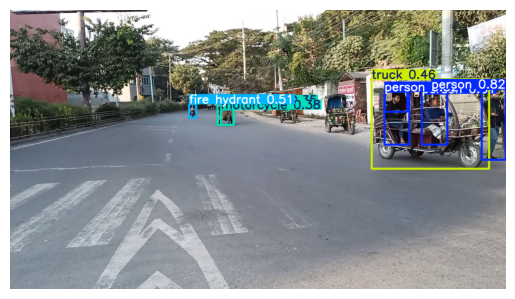


0: 384x640 4 persons, 1 motorcycle, 1 truck, 1 fire hydrant, 8.7ms
Speed: 3.0ms preprocess, 8.7ms inference, 4.4ms postprocess per image at shape (1, 3, 384, 640)


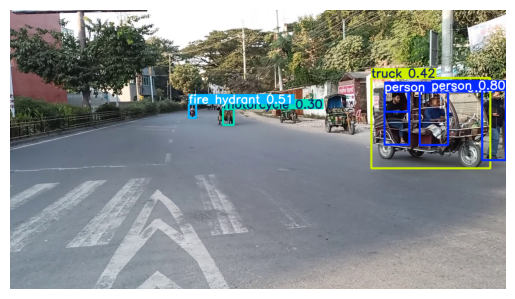


0: 384x640 3 persons, 3 motorcycles, 1 truck, 1 fire hydrant, 13.9ms
Speed: 4.5ms preprocess, 13.9ms inference, 4.5ms postprocess per image at shape (1, 3, 384, 640)


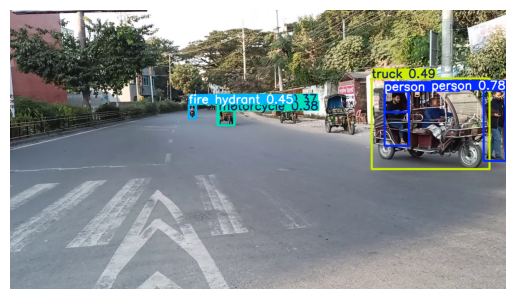


0: 384x640 3 persons, 3 motorcycles, 1 truck, 9.0ms
Speed: 5.4ms preprocess, 9.0ms inference, 4.1ms postprocess per image at shape (1, 3, 384, 640)


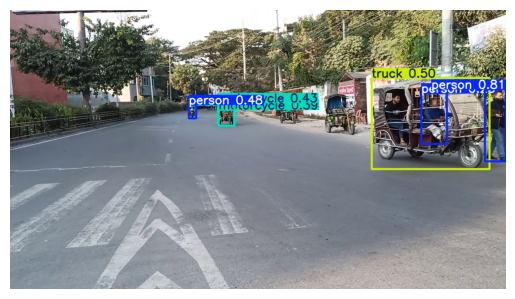


0: 384x640 5 persons, 3 motorcycles, 1 truck, 16.9ms
Speed: 2.0ms preprocess, 16.9ms inference, 4.8ms postprocess per image at shape (1, 3, 384, 640)


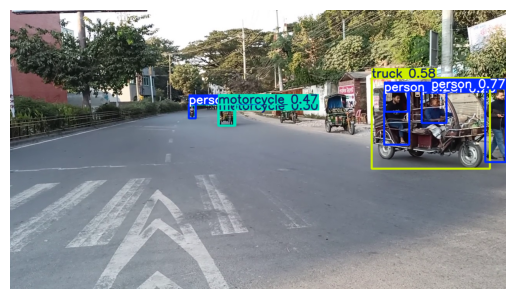


0: 384x640 5 persons, 2 motorcycles, 1 truck, 13.5ms
Speed: 3.7ms preprocess, 13.5ms inference, 4.6ms postprocess per image at shape (1, 3, 384, 640)


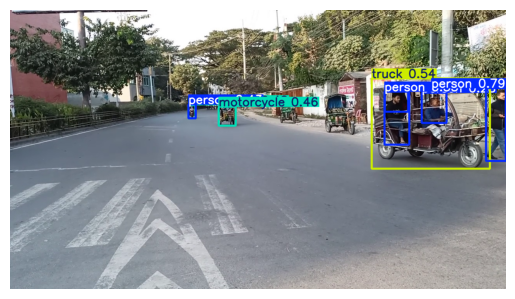


0: 384x640 5 persons, 3 motorcycles, 1 truck, 8.7ms
Speed: 4.2ms preprocess, 8.7ms inference, 4.9ms postprocess per image at shape (1, 3, 384, 640)


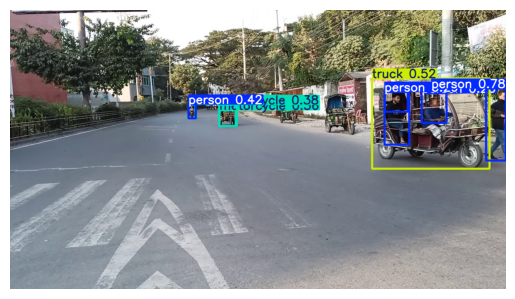


0: 384x640 5 persons, 2 motorcycles, 1 truck, 10.8ms
Speed: 2.5ms preprocess, 10.8ms inference, 4.6ms postprocess per image at shape (1, 3, 384, 640)


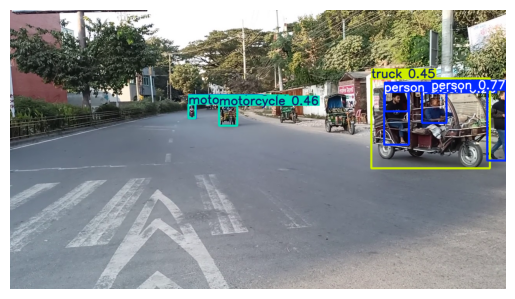


0: 384x640 4 persons, 2 motorcycles, 1 truck, 12.1ms
Speed: 7.0ms preprocess, 12.1ms inference, 4.2ms postprocess per image at shape (1, 3, 384, 640)


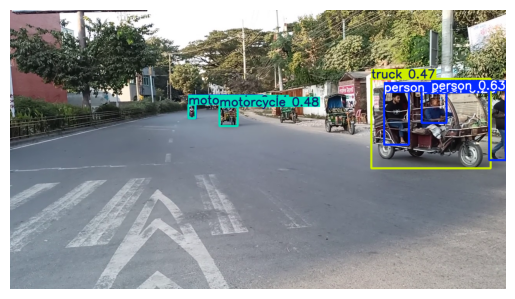


0: 384x640 4 persons, 2 motorcycles, 1 truck, 8.1ms
Speed: 2.9ms preprocess, 8.1ms inference, 4.1ms postprocess per image at shape (1, 3, 384, 640)


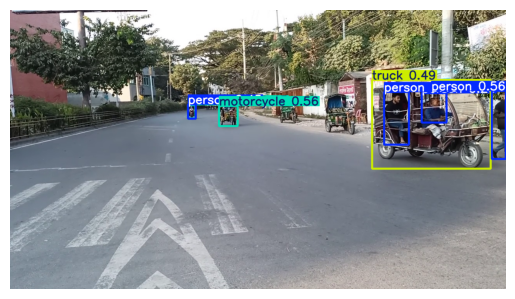


0: 384x640 4 persons, 2 motorcycles, 2 trucks, 13.9ms
Speed: 4.6ms preprocess, 13.9ms inference, 4.4ms postprocess per image at shape (1, 3, 384, 640)


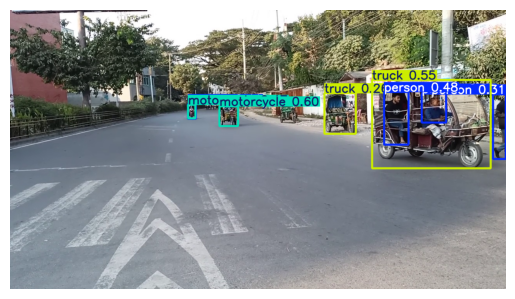


0: 384x640 5 persons, 2 motorcycles, 2 trucks, 7.2ms
Speed: 3.3ms preprocess, 7.2ms inference, 5.0ms postprocess per image at shape (1, 3, 384, 640)


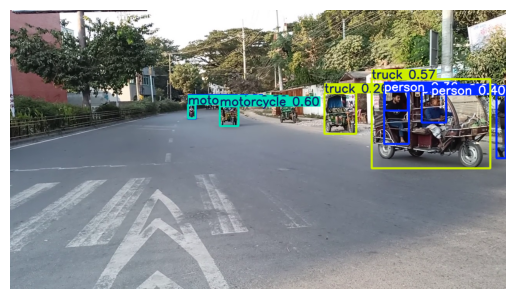


0: 384x640 3 persons, 2 motorcycles, 2 trucks, 9.4ms
Speed: 4.0ms preprocess, 9.4ms inference, 4.1ms postprocess per image at shape (1, 3, 384, 640)


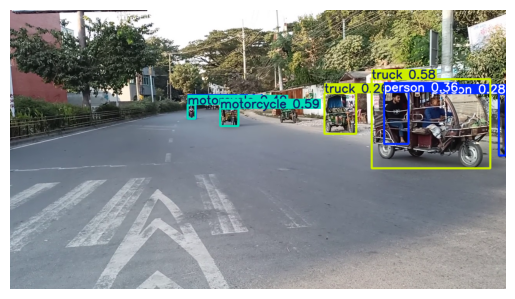


0: 384x640 2 persons, 2 motorcycles, 2 trucks, 9.1ms
Speed: 2.3ms preprocess, 9.1ms inference, 4.3ms postprocess per image at shape (1, 3, 384, 640)


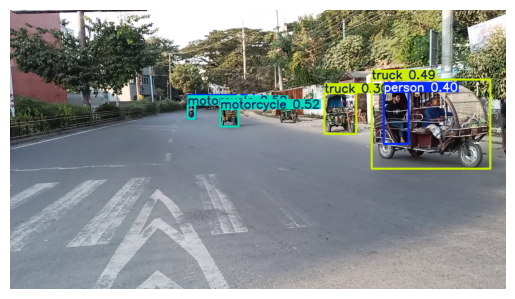


0: 384x640 3 persons, 2 motorcycles, 1 truck, 18.4ms
Speed: 5.0ms preprocess, 18.4ms inference, 4.3ms postprocess per image at shape (1, 3, 384, 640)


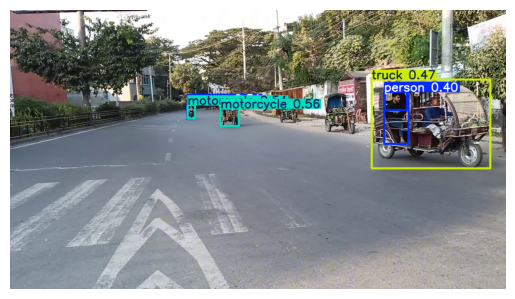


0: 384x640 4 persons, 5 motorcycles, 1 truck, 1 fire hydrant, 10.8ms
Speed: 3.6ms preprocess, 10.8ms inference, 5.6ms postprocess per image at shape (1, 3, 384, 640)


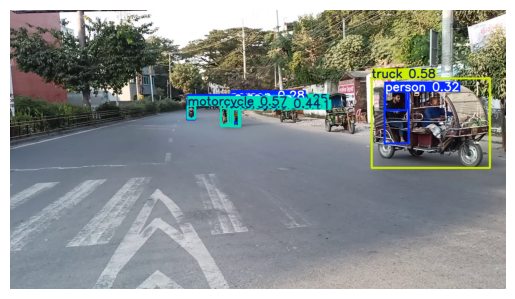


0: 384x640 3 persons, 5 motorcycles, 1 truck, 1 fire hydrant, 14.0ms
Speed: 5.0ms preprocess, 14.0ms inference, 5.4ms postprocess per image at shape (1, 3, 384, 640)


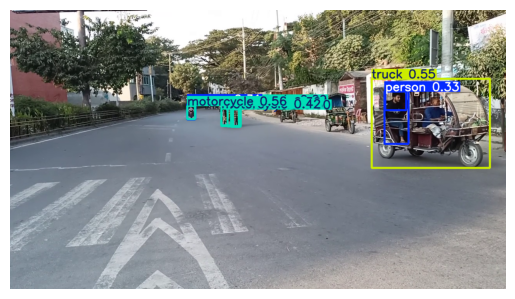


0: 384x640 2 persons, 3 motorcycles, 1 truck, 8.1ms
Speed: 2.0ms preprocess, 8.1ms inference, 4.6ms postprocess per image at shape (1, 3, 384, 640)


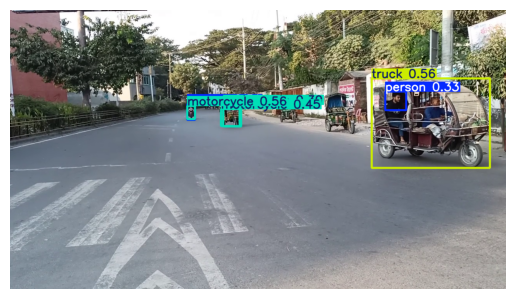


0: 384x640 3 persons, 2 motorcycles, 1 truck, 10.7ms
Speed: 4.2ms preprocess, 10.7ms inference, 3.8ms postprocess per image at shape (1, 3, 384, 640)


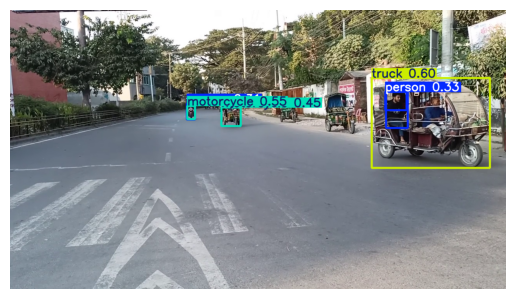


0: 384x640 3 persons, 2 motorcycles, 1 truck, 12.1ms
Speed: 5.1ms preprocess, 12.1ms inference, 3.8ms postprocess per image at shape (1, 3, 384, 640)


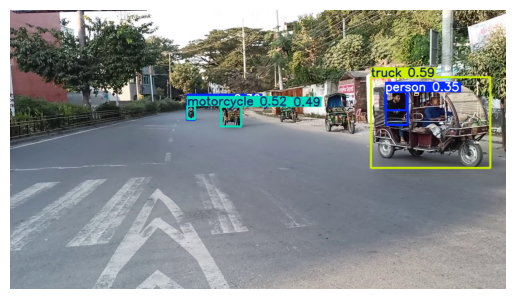


0: 384x640 3 persons, 2 motorcycles, 1 truck, 1 fire hydrant, 12.3ms
Speed: 5.4ms preprocess, 12.3ms inference, 3.9ms postprocess per image at shape (1, 3, 384, 640)


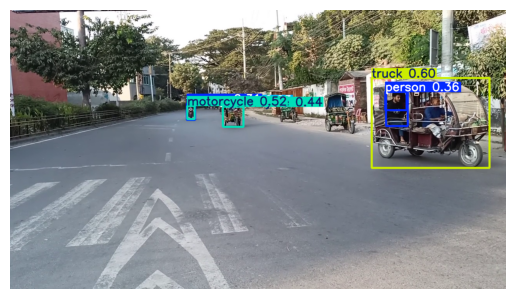


0: 384x640 3 persons, 2 motorcycles, 2 trucks, 8.2ms
Speed: 2.2ms preprocess, 8.2ms inference, 4.4ms postprocess per image at shape (1, 3, 384, 640)


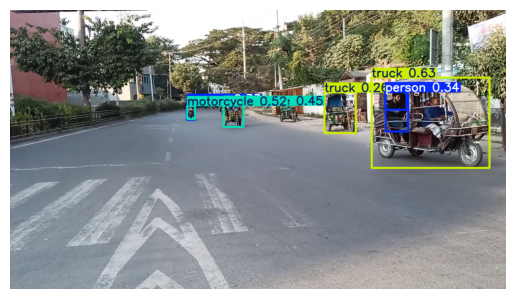


0: 384x640 3 persons, 2 motorcycles, 2 trucks, 1 fire hydrant, 15.5ms
Speed: 2.0ms preprocess, 15.5ms inference, 4.5ms postprocess per image at shape (1, 3, 384, 640)


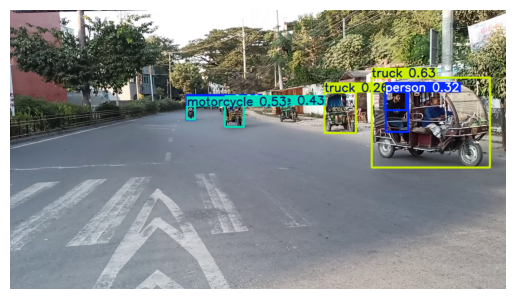


0: 384x640 3 persons, 2 motorcycles, 2 trucks, 1 fire hydrant, 11.9ms
Speed: 5.0ms preprocess, 11.9ms inference, 4.5ms postprocess per image at shape (1, 3, 384, 640)


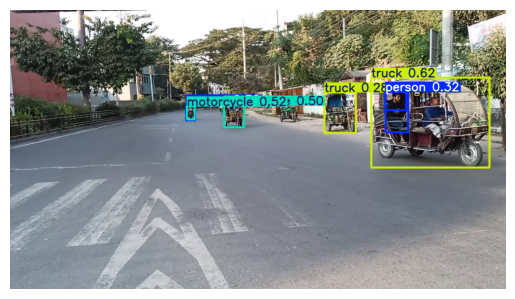


0: 384x640 3 persons, 2 motorcycles, 2 trucks, 8.1ms
Speed: 3.9ms preprocess, 8.1ms inference, 4.3ms postprocess per image at shape (1, 3, 384, 640)


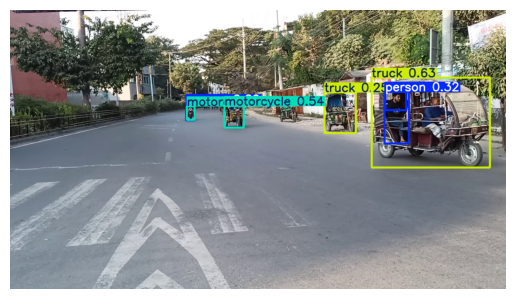


0: 384x640 3 persons, 2 motorcycles, 1 truck, 8.9ms
Speed: 2.6ms preprocess, 8.9ms inference, 3.9ms postprocess per image at shape (1, 3, 384, 640)


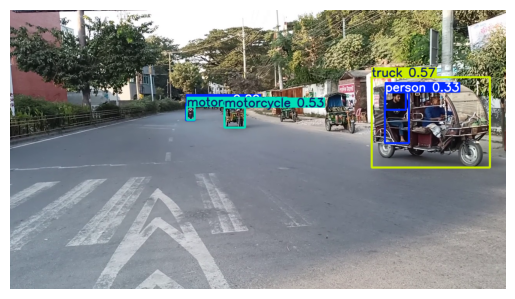


0: 384x640 4 persons, 2 motorcycles, 1 truck, 9.7ms
Speed: 2.3ms preprocess, 9.7ms inference, 4.4ms postprocess per image at shape (1, 3, 384, 640)


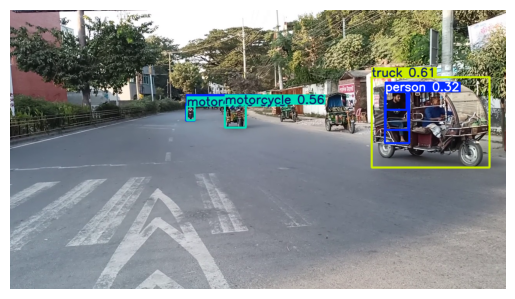


0: 384x640 4 persons, 2 motorcycles, 1 truck, 11.4ms
Speed: 3.7ms preprocess, 11.4ms inference, 4.2ms postprocess per image at shape (1, 3, 384, 640)


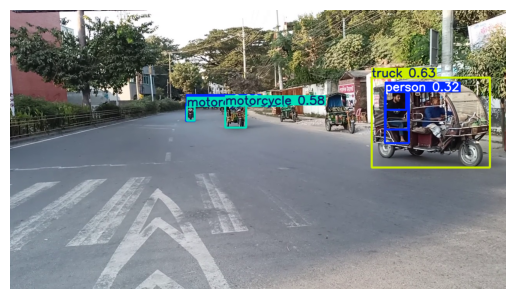


0: 384x640 4 persons, 2 motorcycles, 1 truck, 8.2ms
Speed: 2.7ms preprocess, 8.2ms inference, 4.1ms postprocess per image at shape (1, 3, 384, 640)


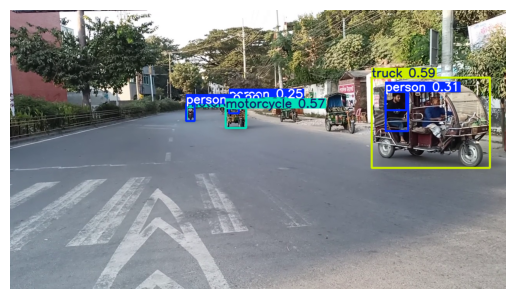


0: 384x640 5 persons, 2 motorcycles, 1 truck, 8.2ms
Speed: 2.5ms preprocess, 8.2ms inference, 4.5ms postprocess per image at shape (1, 3, 384, 640)


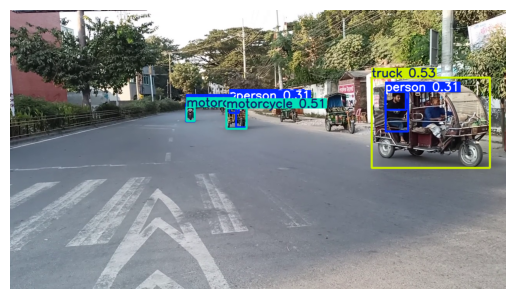


0: 384x640 3 persons, 2 motorcycles, 1 truck, 8.5ms
Speed: 3.3ms preprocess, 8.5ms inference, 4.6ms postprocess per image at shape (1, 3, 384, 640)


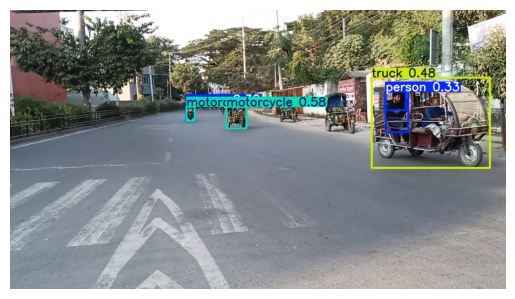


0: 384x640 3 persons, 2 motorcycles, 1 truck, 8.6ms


In [ ]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time

# Load the YOLO model for object detection
from ultralytics import YOLO
model = YOLO('yolov8n.pt')

video_path = '/content/traffic-video-dataset/Talaimari/North-East.mp4'
cap = cv2.VideoCapture(video_path)

# Process and visualize frames
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    results = model(frame)
    annotated_frame = results[0].plot()  # Draw bounding boxes

    # Convert BGR to RGB for matplotlib
    annotated_frame = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

    # Display inside Colab
    plt.imshow(annotated_frame)
    plt.axis('off')
    display(plt.gcf())

    time.sleep(0.05)  # small delay to simulate video playbackimport cv2
    plt.close()

cap.release()
print("Done displaying video.")

## **Optional: Advanced Techniques**
### **Task:**
Explore advanced techniques like:
- **Anomaly detection** (e.g., accidents or traffic jams)
- **Traffic flow prediction** using time series analysis
- **Integration with IoT devices** for real-time data collection


## **Conclusion**
This project provides a comprehensive approach to building an intelligent traffic monitoring and analysis system using **computer vision** and **machine learning**. By automating traffic monitoring, we can improve road safety, reduce congestion, and enhance traffic management.

---